# Searching for the model's algorithm switch: DAS on bf16 Qwen3-8B (demo)

**Question.** Asked to *"implement a path-search algorithm"*, does an LLM always write the same default? Can bans, random "seeds", *"make a new algorithm"* instructions or a direct edit of its activations push it toward a different algorithm? And where inside the model is that choice carried?

**What the experiment did** (artifact `art_veI9l_Rb9wDY`, entry point `method.py`).
- *The default.* bf16 Qwen3-8B (thinking off) almost always writes one default algorithm per coding task: **Dijkstra** for weighted shortest paths (task T2), union-find for connected components (T10), and a full sort for the k-th smallest element (T03).
- *Bans substitute.* A ban (*"Write a correct solution that does not use Dijkstra's algorithm."*) makes it write the runner-up, **Bellman-Ford/SPFA**.
- *The question asked.* Is that choice carried by a **low-rank linear subspace** of the task-specification activations?
- *The method.* **Distributed alignment search (DAS)** fits one orthonormal map `R` (4096 x 16, nested ranks k = 1..16) at decoder blocks 12-23. The interchange intervention then writes the ban prompt's activations into a neutral "twin" prompt only inside that subspace.
- *The test.* **Held-out generation** on 30 common-random-number (CRN) slots per cell; every program is run against hidden tests and labelled by algorithm.
- *The comparisons.* The ceiling is the full-state exchange at the same site. The controls are random subspaces, permuted-label DAS, read-position DAS, DIM-1, PCA-16 and a randomly initialised network.

**Headline of the full run** (4,500 generated programs, about 1.6 GPU-hours on one RTX 4090):
- *A low-rank handle.* A rank-2 DAS edit moves T2 to Bellman-Ford about as often as the full-state exchange does: 12/30 vs 11/30, against 1/30 for the unedited base. Random subspaces of the same rank do nothing (at most 1/30).
- *…that is not specific.* A map fitted on **permuted labels** steers too (15/30), and a randomly initialised network admits an equally good teacher-forced fit. So **P1 FAILS** on every task: what was found is a strong low-rank *steering handle*, not a clean causal "algorithm variable".
- *M, the manifold.* In the DAS coordinates, bans leave the cloud of default-prompt paraphrases along the Dijkstra -> Bellman-Ford axis. Random seeds (`seed=d32qxk4nt43`), *"Make a new algorithm."* and a 2,000-word novelty instruction stay inside the cloud.
- *Behaviour agrees.* Both random seeds and *"Make a new algorithm."* keep Dijkstra on 30/30, and the semantic seed keeps it on 28/30. Only the long novelty instruction moves anything: 6/30 Bellman-Ford, which is the runner-up and nothing novel.
- *R, the λ sweep.* Scaling the edit by λ changes behaviour gradually: a dial, not a switch.

**What this notebook runs.**
- *Not here: the GPU stages.* They need the 16 GB model on a 24 GB GPU; section 1 lists them.
- *Re-run inline: the CPU stages of `method.py`.* These are `report` (`src/analysis7.py`, `src/m7.py`, `src/figures7.py`) and `audit` (`audit/rederive*.py`), using the original functions on `mini_demo_data.json`.
- *The demo data.*
  - **100 T2 generation rows**: the held-out W5-ban source with every arm, its full-state ceiling, the λ sweep and the unedited twin.
  - **The real 16-d activation coordinates** of 151 T2 prompts in the fitted DAS subspace.
  - The reported result files, for comparison.

It runs on a CPU in well under a minute once the packages are installed, and Colab has them all pre-installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, scipy, scikit-learn, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions).
# The analysis stages replayed here need nothing else; the GPU stages of the original run (torch, transformers,
# accelerate, the 16 GB model) are not run in this notebook.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py ----
import subprocess
import sys
from pathlib import Path

# ---- src/report7.py, src/stats6.py, src/analysis7.py, src/m7.py, src/figures7.py, audit/rederive*.py ----
import json
import math
import random
from collections import Counter, defaultdict
from typing import Any

import numpy as np
from scipy import stats

import matplotlib.pyplot as plt  # figures7.py also calls matplotlib.use("Agg"); the notebook keeps the inline backend

# ---- notebook only ----
import re  # restores arm names such as LAM0_5_ban_k2 -> LAM0.5_ban_k2 when the label rows are rebuilt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-33/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
md = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]
print(md["method_name"], "|", md["model"])
print(f"dataset {data['datasets'][0]['dataset']}: {len(EXAMPLES)} examples by source group {md['demo_subset']['groups']}")
ex0 = EXAMPLES[0]
print("\nexample 0 = W5 ban source, CRN slot 0. Base prompt (the neutral twin the edits are written into):")
print("   ", ex0["input"][:300].replace("\n", " "), "...")
print("expected landing algorithm:", ex0["output"])
print("label|verdict per arm:", {k[len("predict_"):]: v for k, v in ex0.items() if k.startswith("predict_")})

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Finding the model's hidden algorithm switch (iteration 7, bf16 Qwen3-8B) | Qwen/Qwen3-8B@b968826d (bf16, thinking off)
dataset T2_weighted_shortest_path: 100 examples by source group {'ban_W5': 30, 'confirm_ban': 30, 'R_lambda_ban_k2': 20, 'stage0_TWIN': 20}

example 0 = W5 ban source, CRN slot 0. Base prompt (the neutral twin the edits are written into):
    Write a correct solution that does not use man and the house.  Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, eac ...
expected landing algorithm: bf_spfa
label|verdict per arm: {'BASE_PAD': 'dijkstra|pass', 'BASE_W5': 'dijkstra|pass', 'DASLY2_ban_k1': 'dijkstra|pass', 'DASLY2_ban_k16': 'dijkstra|pass', 'DASLY2_ban_k2': 'dijkstra|pass', 'DASLY_b

## Configuration
Every tunable parameter is set here. The original run's values are given in the comments and in this table; the CPU analysis runs in seconds at the original values.

| parameter | original | used by |
|---|---|---|
| `N` | 30 | CRN slots per generation cell (`analysis7.N`, `rederive.N`). A lower value scores only the first N slots, and the numbers then differ from the full run. |
| `BOOT` | 2000 | slot-cluster bootstrap repetitions for the recovery CIs (`analysis7.BOOT`); at least 100 are needed for a CI |
| `MDS_N_INIT` | 4 | metric-MDS restarts (`m7.analyse`) |
| `ISOMAP_NEIGHBORS` | 10 | Isomap neighbourhood (`m7.analyse`) |
| `GEODESIC_KNN` | (5, 10, 15) | kNN graphs of the geodesic analysis; it must contain 10, which F5 and the summary use |
| `N_RANK_NULL` | 1000 | random relabellings in the leave-one-survivor placement test (`m7.analyse`) |
| `RUN_PIPELINE_STAGES` | `[]` | `method.py` stages to really run. This needs the cloned experiment folder with its `.venv`; the GPU stages also need a 24 GB GPU and the model. |

In [5]:
# All values are the original run's (the CPU analysis takes seconds); smaller ones give a quicker smoke test
# (tested: N = 10, BOOT = 100, MDS_N_INIT = 1, GEODESIC_KNN = (10,), N_RANK_NULL = 10).
N = 30                    # CRN slots scored per cell (original: 30)
BOOT = 2000               # bootstrap repetitions for recovery CIs (original: 2000)
MDS_N_INIT = 4            # metric-MDS restarts (original: 4)
ISOMAP_NEIGHBORS = 10     # Isomap kNN (original: 10)
GEODESIC_KNN = (5, 10, 15)  # kNN graphs for geodesic distances (original: (5, 10, 15)); must contain 10
N_RANK_NULL = 1000        # random relabellings for the leave-one-survivor test (original: 1000)
RUN_PIPELINE_STAGES = []  # e.g. ["report", "audit"] inside the cloned experiment folder (GPU stages need a 24 GB GPU)

## 1. The original entry point: `method.py`
`method.py` runs every stage in the order it was run. Each stage is a separate, resumable script in `src/`, and the stages fall into two groups.

- **GPU stages, not run here.** `utest`, `s0`, `profile`, `fit`, `fitly`, `gen` and `after` load bf16 Qwen3-8B (16.4 GB) onto one 24 GB GPU.
  - They sample programs with exact common random numbers.
  - They fit the DAS maps and edit the activations at the task-spec positions during the prefill.
  - Together they generated the 4,500 programs in about 1.6 GPU-hours.
- **CPU stages, replayed below.** `report` and `audit` turn the labelled rows into every number of the paper. The rest of the notebook re-runs them inline on the demo data.

The script is shown as written, with two notebook adaptations. `ROOT` is the current folder, because a notebook has no `__file__`. `main()` receives the stage list instead of reading `sys.argv`. It runs the stages listed in `RUN_PIPELINE_STAGES` only inside the cloned experiment folder, which holds `src/` and `.venv/`.

In [6]:
# ---- method.py (verbatim; notebook changes are marked "notebook:") ----
METHOD_DOC = """Iteration 7 entry point: DAS localisation of the planned algorithm in bf16 Qwen3-8B, validated by generation.

Runs every stage in the order it was run (each stage is resumable; GPU stages skip finished sample ids / files):
  prompts   src/prompts7.py                 all prompt records + CPU tests (prompts/prompts7.jsonl)
  commit0   src/prereg7.py                  commit #0 (design, thresholds, predictions; hash chain)
  label     src/label7.py (background)      frozen labellers follow data/samples_raw.jsonl -> data/labels.jsonl
  utest     src/run_gpu7.py utest           U1-U8 (results/unit_tests_gpu.json)
  s0        src/run_gpu7.py s0              Stage 0 sampling T2, T10, T03
  targets   stages_b7.stage_targets         kept Y, ban landing set, target programs (commit1_<task>_v2)
  profile   src/run_gpu7.py profile         layer profile + generation confirmation -> site (commit1b_<task>)
  fit       src/run_gpu7.py fit/fitlight    committed contrastive DAS fits + controls (commit2_<task>)
  fitly     src/run_gpu7.py fitly           amendment 1: bounded LME_Y maps (MAIN_LY, PERM_LY, RPOS_LY)
  tfeval    src/run_gpu7.py tfeval          held-out teacher-forced evaluation
  gen       src/run_gpu7.py gen,genpilot    held-out generation (MAIN_LY full cell set; MAIN 10-slot pilot)
  after     scripts/run_gpu_after.sh        R sweep + M states (T2), third task T03, random-init network (T2)
  report    src/report7.py                  every analysis + figures (results/*.json, figures/)
  novelty   src/novelty6.py                 two-family novelty audit of correct 'other' programs
  outputs   src/outputs7.py                 method_out.json (+ full_/mini_/preview_), schema-validated
  audit     audit/rederive.py               independent stdlib re-derivation + placebo tests

usage: .venv/bin/python method.py [stage ...]   (no argument = the whole pipeline)
"""

ROOT = Path.cwd()  # notebook: a notebook has no __file__ (original: Path(__file__).resolve().parent)
PY = str(ROOT / ".venv" / "bin" / "python")


def run(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run(list(args), cwd=ROOT, check=True)


STAGES = {
    "prompts": lambda: run(PY, "src/prompts7.py"),
    "commit0": lambda: run(PY, "src/prereg7.py"),
    "utest": lambda: run(PY, "src/run_gpu7.py", "utest", "--tasks", "T2"),
    "s0": lambda: run(PY, "src/run_gpu7.py", "s0", "--tasks", "T2,T10,T03"),
    "targets": lambda: run(PY, "-c", "import sys; sys.path.insert(0,'src'); from cfg import setup_logging; "
                                     "setup_logging('targets7'); from prompts7 import load_tokenizer; import stages_b7 "
                                     "as B; tok=load_tokenizer(); [B.stage_targets(t, tok) for t in "
                                     "('T2','T10','T03')]"),
    "profile": lambda: run(PY, "src/run_gpu7.py", "profile", "--tasks", "T2,T10"),
    "fit": lambda: (run(PY, "src/run_gpu7.py", "fit", "--tasks", "T2"),
                    run(PY, "src/run_gpu7.py", "fitlight", "--tasks", "T10")),
    "fitly": lambda: run(PY, "src/run_gpu7.py", "fitly,tfeval", "--tasks", "T2,T10"),
    "gen": lambda: run(PY, "src/run_gpu7.py", "gen,genpilot", "--tasks", "T2,T10"),
    "after": lambda: run("bash", "scripts/run_gpu_after.sh"),
    "report": lambda: run(PY, "src/report7.py"),
    "novelty": lambda: run(PY, "src/novelty6.py"),
    "outputs": lambda: run(PY, "src/outputs7.py"),
    "audit": lambda: run("python3", "audit/rederive.py"),
}


def main(argv: list[str]) -> None:
    want = argv or list(STAGES)  # notebook: stage list passed in (original: want = sys.argv[1:] or list(STAGES))
    label = None
    if any(s in want for s in ("utest", "s0", "profile", "fit", "fitly", "gen", "after")):
        label = subprocess.Popen([PY, "src/label7.py"], cwd=ROOT)
    try:
        for s in want:
            STAGES[s]()
    finally:
        if label is not None:
            (ROOT / "results" / "gpu_all_done.flag").touch()
            label.wait()


# notebook: run the pipeline only inside the cloned experiment folder; otherwise show what it would run
if RUN_PIPELINE_STAGES and (ROOT / "src" / "run_gpu7.py").exists():
    main(RUN_PIPELINE_STAGES)
else:
    print(METHOD_DOC)
    print("-> not run here. The CPU stages 'report' and 'audit' are replayed inline below on mini_demo_data.json.")

Iteration 7 entry point: DAS localisation of the planned algorithm in bf16 Qwen3-8B, validated by generation.

Runs every stage in the order it was run (each stage is resumable; GPU stages skip finished sample ids / files):
  prompts   src/prompts7.py                 all prompt records + CPU tests (prompts/prompts7.jsonl)
  commit0   src/prereg7.py                  commit #0 (design, thresholds, predictions; hash chain)
  label     src/label7.py (background)      frozen labellers follow data/samples_raw.jsonl -> data/labels.jsonl
  utest     src/run_gpu7.py utest           U1-U8 (results/unit_tests_gpu.json)
  s0        src/run_gpu7.py s0              Stage 0 sampling T2, T10, T03
  targets   stages_b7.stage_targets         kept Y, ban landing set, target programs (commit1_<task>_v2)
  profile   src/run_gpu7.py profile         layer profile + generation confirmation -> site (commit1b_<task>)
  fit       src/run_gpu7.py fit/fitlight    committed contrastive DAS fits + controls (commit2_

## 2. Constants of the experiment (`src/cfg7.py`)
These are copied verbatim from `src/cfg7.py`:
- the tasks and each task's default algorithm;
- the algorithm vocabulary of the frozen labellers;
- the DAS ranks, the profiled blocks and the fallback band;
- the seeds;
- the exact seed strings and instructions that the manifold analysis places.

In [7]:
# ---- src/cfg7.py (the constants used by the CPU analyses; verbatim) ----
TASKS7 = ("T2", "T10", "T03")
CORE7 = ("T2", "T10")
DEFAULT7 = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}
# label vocabulary of the frozen labellers (exp8 suite for T2, exp11 bench for T10/T03)
CATALOGUE7 = {
    "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
    "T10": ["bfs", "dfs", "union_find", "label_propagation"],
    "T03": ["full_sort", "size_k_heap", "heapify_pop", "quickselect", "median_of_medians", "counting_sort"],
}
FORCED_TEMPLATES7 = ("Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
                     "Your solution should use {j}.", "Write an implementation based on {j}.")  # bench k = 0..4
TRAIN_W = ("W1", "W2", "W3")
HELD_W = "W5"
W4 = "W4"
RANKS = (1, 2, 4, 8, 16)
K_MAX = 16
PROFILE_LAYERS = tuple(range(10, 27, 2))           # 10, 12, ..., 26
BAND = tuple(range(12, 24))                          # declared fallback band 12-23
SEEDS = {"das_init": {"T2": 7001 + 2, "T10": 7001 + 10, "T03": 7001 + 3}, "random_subspaces": (9001, 9002, 9003),
         "permutation": 7101, "random_init_network": 0, "mds": 0, "boot": 20261022, "split": 7007}
MAX_NEW7 = {"T2": 512, "T10": 384, "T03": 384}       # exp30 caps (logged deviation D-cap)
SEED_STRINGS = {"seed_rand1": "seed=d32qxk4nt43", "seed_rand2": "seed=(horse chair roof love)"}
INSTR = {"instr_new": "Make a new algorithm.",
         # exp18 src/config.py LONGFORM['LF2'] verbatim (ITER3/gen_art_experiment_18)
         "instr_novel": ("Make a fully novel algorithm never seen before for this task. Before writing any code, write "
                         "a design rationale of about 2,000 words that explains the idea, why no one has used it "
                         "before, and why it is correct.")}

### The run folder, backed by the demo data
The analysis code reads `results/*.json`, `data/labels.jsonl`, `prompts/prompts7.jsonl` and the cached activations through a few helpers: `read_json`, `read_jsonl`, `results7(...)`, `ROOT / ...` and `.exists()` (`src/cfg.py`, `src/cfg7.py`). The notebook keeps those names but backs them with `mini_demo_data.json`, so **the analysis functions below are pasted unchanged**.

The label rows of `data/labels.jsonl` are rebuilt from the output format, one row per `predict_<arm>` field of each example:
- `label|pass` gives `label` and `passed`;
- `metadata_slot` gives the CRN `slot_index`;
- `finish_reason` comes from `metadata_edit_<arm>`;
- the `stage` follows from the arm.

The output format stored the λ arms as `LAM0_5_ban_k2`, so their decimal point is restored (`LAM0.5_ban_k2`).

In [8]:
# ---- notebook: stand-ins for the run folder (src/cfg.py ROOT / read_json / read_jsonl / FIG_DIR, src/cfg7.py results7 / LABELS7)
class DemoPath(str):
    """A path inside the original experiment folder; read_json / read_jsonl / exists() look it up in FILES."""

    def __truediv__(self, other: str) -> "DemoPath":
        return DemoPath(f"{self}/{other}" if self else str(other))

    @property
    def name(self) -> str:
        return self.rsplit("/", 1)[-1]

    def exists(self) -> bool:
        return str(self) in FILES


ROOT = DemoPath("")
FIG_DIR = Path("figures")
LABELS7 = ROOT / "data" / "labels.jsonl"


def results7(name: str) -> DemoPath:
    return ROOT / "results" / name


def read_json(p: DemoPath) -> Any:
    return FILES[str(p)]


def read_jsonl(p: DemoPath) -> list[dict[str, Any]]:
    return FILES[str(p)]


def rows_from_examples(examples: list[dict[str, Any]], task: str = "T2") -> list[dict[str, Any]]:
    """data/labels.jsonl rows rebuilt from the exp_gen_sol_out examples: one row per predict_<arm> field."""
    rows = []
    for e in examples:
        for key, v in e.items():
            if not key.startswith("predict_"):
                continue
            arm0 = key[len("predict_"):]
            label, verdict = v.rsplit("|", 1)
            edit = json.loads(e.get(f"metadata_edit_{arm0}") or "{}")
            arm = re.sub(r"^LAM(\d+)_(\d+)_", r"LAM\1.\2_", arm0)  # LAM0_5_ban_k2 -> LAM0.5_ban_k2
            stage = ("mgen" if arm.startswith("MGEN_") else "r" if arm.startswith("LAM") else
                     "stage0" if e["metadata_group"].startswith("stage0_") else "gen")
            rows.append({"task": task, "arm": arm, "slot_index": int(e["metadata_slot"]), "label": label,
                         "passed": verdict == "pass", "stage": stage, "finish_reason": edit.get("finish_reason"),
                         "sample_id": f"{task}|{arm}|{e['metadata_slot']}", "code": e.get(f"metadata_code_{arm0}")})
    return rows


FILES = {str(LABELS7): rows_from_examples(EXAMPLES),
         str(ROOT / "prompts" / "prompts7.jsonl"): md["prompts_T2"],
         str(ROOT / "inputs" / "exp24_T2_base_samples.jsonl"): md["inputs"]["exp24_T2_base_samples"],
         str(ROOT / "inputs" / "exp29_T2_labels.jsonl"): md["inputs"]["exp29_T2_labels"],
         **{str(results7(f"{name}.json")): v for name, v in md["results"].items()}}
labels_demo = read_jsonl(LABELS7)
print(f"{len(labels_demo)} label rows, {len({r['arm'] for r in labels_demo})} arms, stages "
      f"{dict(Counter(r['stage'] for r in labels_demo))}")
print("reported results files available:", sorted(k for k in FILES if k.startswith("results/")))

1110 label rows, 44 arms, stages {'gen': 710, 'mgen': 180, 'r': 200, 'stage0': 20}
reported results files available: ['results/kstar_T2.json', 'results/m_behaviour.json', 'results/m_manifold.json', 'results/p1.json', 'results/p1_controls_T2.json', 'results/r_discreteness.json', 'results/randinit_ly_T2.json', 'results/site_T2.json', 'results/targets_T2.json', 'results/tf_eval_T2.json', 'results/tf_eval_T2_LY.json']


## 3. What the model writes, arm by arm (`report` stage: `report7.cell_table`)
Every arm of a slot shares that slot's uniform random stream (exact common random numbers, T = 1). Two arms on the same slot therefore differ only by the activation edit or the prompt. The table counts **correct** programs (hidden tests passed) by the algorithm the frozen labellers assign. In arm names, `_ban` means the W5 ban is the source and `_k<k>` is the rank of the edit.

| arm | what it is |
|---|---|
| `BASE_W5` | the unedited **twin** prompt (the W5 ban template with a neutral noun, e.g. *"...does not use man."*); the base of every interchange |
| `FULL_ban_band` / `FULL_ban_L18` | the twin run with the W5 ban's **full** task-spec states written in at blocks 12-23 / block 18 (the ceiling) |
| `DASLY_ban_k{k}` | only the rank-k subspace of the fitted DAS map (amended LME_Y objective) is written in |
| `RAND_ban_*`, `PERMLY_ban_*` | random rank-k subspaces; DAS fitted on permuted labels |
| `RPOSLY_ban_k16`, `RPOSFULL_ban`, `DIM1_ban`, `PCA16_ban` | read-position DAS / full state, difference-in-means direction, PCA-16 |
| `DAS_ban_k*`, `DASLY2_ban_k*` | the committed contrastive map (diverged, see amendment 1); a second init seed |
| `MGEN_*` | **unedited** prompts that the manifold analysis places: plain P0, two random seeds, a semantic seed, two novelty instructions |
| `LAM{λ}_ban_k2` | the rank-2 edit scaled by λ (the R sweep, N = 20) |
| `TWIN` | Stage-0 unedited twin (N = 20) |

In [9]:
# ---- src/report7.py (verbatim) ----
def fmt(x: Any, nd: int = 2) -> str:
    if x is None:
        return "-"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def cell_table(task: str) -> list[dict[str, Any]]:
    from collections import Counter
    rows = [r for r in read_jsonl(LABELS7) if r["task"] == task and r.get("stage") in ("gen", "r", "mgen")]
    by = {}
    for r in rows:
        by.setdefault(r["arm"], []).append(r)
    out = []
    for arm, rs in sorted(by.items()):
        corr = Counter(r["label"] for r in rs if r.get("passed"))
        out.append({"arm": arm, "n": len(rs), "pass": sum(bool(r.get("passed")) for r in rs) / len(rs),
                    "correct_composition": dict(corr.most_common()),
                    "n_length": sum(r.get("finish_reason") == "length" for r in rs)})
    return out


# ---- notebook: print the table (report7 writes it to results/cells.json) ----
cells = cell_table("T2")
twin = Counter(r["label"] for r in read_jsonl(LABELS7) if r["arm"] == "TWIN" and r["passed"])
print(f"Stage-0 unedited twin, N = 20: correct programs {dict(twin)}\n")
print(f"{'arm':<20}{'n':>4}{'pass':>7}{'trunc':>7}   correct programs by algorithm")
for c in cells:
    print(f"{c['arm']:<20}{c['n']:>4}{fmt(c['pass']):>7}{c['n_length']:>7}   {c['correct_composition']}")

Stage-0 unedited twin, N = 20: correct programs {'dijkstra': 20}

arm                    n   pass  trunc   correct programs by algorithm
BASE_PAD              30   0.97      0   {'dijkstra': 29}
BASE_W5               30   0.97      0   {'dijkstra': 28, 'bf_spfa': 1}
DASLY2_ban_k1         30   0.73      0   {'dijkstra': 19, 'bf_spfa': 3}
DASLY2_ban_k16        30   0.67      0   {'dijkstra': 13, 'bf_spfa': 7}
DASLY2_ban_k2         30   0.60      0   {'dijkstra': 9, 'bf_spfa': 8, 'other': 1}
DASLY_ban_k1          30   0.77      0   {'dijkstra': 15, 'bf_spfa': 8}
DASLY_ban_k16         30   0.80      0   {'dijkstra': 18, 'bf_spfa': 6}
DASLY_ban_k2          30   0.83      0   {'dijkstra': 13, 'bf_spfa': 12}
DASLY_ban_k4          30   0.57      0   {'bf_spfa': 10, 'dijkstra': 7}
DASLY_ban_k8          30   0.83      0   {'dijkstra': 15, 'bf_spfa': 10}
DAS_ban_k1            10   0.10      5   {'dijkstra': 1}
DAS_ban_k16           10   0.00      9   {}
DAS_ban_k2            10   0.00      7   {}

## 4. The committed analysis code (`src/stats6.py`, `src/analysis7.py`)
These definitions are verbatim; only `N` and `BOOT` now come from the configuration cell. The definitions below were committed before any held-out generation was scored.
- **correct-Y(row)**: the program passed the hidden tests **and** its algorithm label is in Y(source). For the T2 ban source, Y = {Bellman-Ford/SPFA}, the runner-up.
- **TRANSFER(arm)**: (correct-Y count under the arm − count under the unedited base) / N, on paired CRN slots.
- **RECOVERY_k**: Σ[count(DAS_k) − count(base)] / Σ[count(FULL) − count(base)]. A value of 1 means the rank-k subspace carries everything the full-state exchange carries.

Intervals are Clopper-Pearson for shares and a slot-cluster bootstrap for recoveries. Paired contrasts use the exact McNemar test, Holm-corrected across tasks.

In [10]:
# ---- src/stats6.py (verbatim) ----
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


# ---- src/analysis7.py: data access, sources, recovery, bootstrap, McNemar (verbatim; N, BOOT from the config cell) ----
def arms_of(task: str) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in read_jsonl(LABELS7):
        if r["task"] == task:
            out[r["arm"]][int(r["slot_index"])] = r
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def off_default(r: dict[str, Any] | None, D: str) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") not in (D, "invalid", None))


def vec(A: dict, arm: str, Y: list[str], n: int = N) -> np.ndarray | None:
    if arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(n)])


def pass_rate(A: dict, arm: str, n: int = N) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(n) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def full_ban_arm(task: str) -> str:
    s = read_json(results7(f"site_{task}.json"))
    return "FULL_ban_band" if s["site"] == "band" else f"FULL_ban_L{s['L_star']}"


PREFIX = {"MAIN": ("DAS", "PERM", "PERM", "RPOS", "REV", "NULL"),
          "MAIN_LY": ("DASLY", "PERMLY", "PERM_LY", "RPOSLY", "REVLY", "NULLLY")}
FIT = {"name": "MAIN_LY"}


def sources(task: str) -> list[dict[str, Any]]:
    """Held-out sources with their arm names, base arm and Y set (map FIT['name'])."""
    P, PP = PREFIX[FIT["name"]][:2]
    T = read_json(results7(f"targets_{task}.json"))
    ks = read_json(results7(f"kstar_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full_ban_arm(task),
            "das": {k: f"{P}_ban_k{k}" for k in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     ks["k_star"]: ([f"RAND_ban_k{ks['k_star']}"] if ks["k_star"] != 16 else
                                    ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: f"{PP}_ban_k16", ks["k_star"]: f"{PP}_ban_k{ks['k_star']}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {k: f"{P}_F_{Y}_k{k}" for k in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"{PP}_F_{Y}_k16"}})
    return out


def counts_vec(A: dict, src: dict[str, Any], arm: str) -> np.ndarray | None:
    return vec(A, arm, src["Y"])


def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if which == "das":
            arms = [s["das"].get(k)] if s["das"].get(k) else []
        else:
            arms = s["rand"].get(k, [])
        vs = [counts_vec(A, s, a) for a in arms]
        vs = [v for v in vs if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = 20261022
            ) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(BOOT):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


def mcnemar_das_rand(A: dict, srcs: list[dict[str, Any]], k: int) -> dict[str, Any]:
    b = c = 0
    for s in srcs:
        da = s["das"].get(k)
        ra = (s["rand"].get(k) or [None])[0]
        if not da or not ra or da not in A or ra not in A:
            continue
        v1, v2 = counts_vec(A, s, da), counts_vec(A, s, ra)
        b += int(((v1 == 1) & (v2 == 0)).sum())
        c += int(((v1 == 0) & (v2 == 1)).sum())
    return {"b_das_only": b, "c_rand_only": c, "p": mcnemar_exact(b, c)}

### The committed P1 test and its controls (`p1_task`, `p1_all`, `controls`)
These three functions are verbatim.
- `p1_task` scores each held-out source: base, full-state, DAS (each rank), random and permuted counts. Per rank it then computes the pooled recovery with a bootstrap CI and an exact McNemar test of DAS against random on the same slots.
- `p1_all` evaluates every committed clause at k* or 16, whichever satisfies more of them, and Holm-corrects across tasks. **P1 passes only if all clauses hold**:
  - recovery ≥ 0.8;
  - margin over random ≥ 0.4;
  - McNemar Holm p < 0.01;
  - permuted-label transfer ≤ 0.1;
  - pass rate ≥ 0.8 × base;
  - on T2, a random-init network's fit ratio < 0.5 (the Sutter control).
- `controls` scores the read-position, DIM-1, PCA-16, null-source and W4 arms.

In [11]:
# ---- src/analysis7.py: P1 and controls (verbatim) ----
def p1_task(task: str) -> dict[str, Any]:
    A = arms_of(task)
    srcs = sources(task)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    out: dict[str, Any] = {"task": task, "k_star": ks, "per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = counts_vec(A, s, s["base"]), counts_vec(A, s, s["full"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "rand": {}, "perm": {}}
        for k, a in s["das"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum()
                                else None, "pass": pass_rate(A, a),
                                "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = counts_vec(A, s, a)
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                     "pass": pass_rate(A, a)}
        for k, a in s["perm"].items():
            v = counts_vec(A, s, a)
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "pass": pass_rate(A, a)}
        out["per_source"][s["name"]] = ps
    cand_k = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr, rnum, rden = pooled_recovery(A, srcs, k, which="rand") if k in cand_k else (None, 0, 0)
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand_k:
            e["mcnemar_das_vs_rand"] = mcnemar_das_rand(A, srcs, k)
            perm_tr = []
            for s in srcs:
                a = s["perm"].get(k)
                b = counts_vec(A, s, s["base"])
                v = counts_vec(A, s, a) if a else None
                if v is not None and b is not None:
                    perm_tr.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm_tr) if perm_tr else None
            # pass clause on every DAS arm at k
            pr = []
            for s in srcs:
                a = s["das"].get(k)
                if a and a in A and pass_rate(A, s["base"]):
                    pr.append(pass_rate(A, a) / pass_rate(A, s["base"]))
            e["pass_ratio_min"] = min(pr) if pr else None
        out["per_k"][k] = e
    # slot IIA for the ban source (label equals the full ban prompt's label on the slot)
    ref = A.get("BAN_W5", {})
    iia = {}
    for k in RANKS:
        a = f"{PREFIX[FIT['name']][0]}_ban_k{k}"
        if a in A and ref:
            iia[k] = float(np.mean([A[a][s]["label"] == ref[s]["label"] for s in range(N) if s in A[a] and s in ref]))
    fa = full_ban_arm(task)
    if fa in A and ref:
        iia["full"] = float(np.mean([A[fa][s]["label"] == ref[s]["label"] for s in range(N) if s in A[fa] and s in ref]))
    out["slot_iia_ban"] = iia
    return out


def p1_all(tasks: list[str]) -> dict[str, Any]:
    res = {t: p1_task(t) for t in tasks}
    # choose per task the candidate k (16 or k*) that satisfies the most clauses (smallest p on ties)
    pv = {}
    for t, r in res.items():
        best = None
        for k in sorted({16, r["k_star"]}):
            e = r["per_k"][k]
            if e.get("mcnemar_das_vs_rand") is None:
                continue
            cl = {"recovery_ge_0.8": (e["recovery"] or 0) >= 0.8,
                  "margin_ge_0.4": (e["recovery"] or 0) - (e["random_recovery"] or 0) >= 0.4,
                  "permuted_le_0.1": e["permuted_transfer_max"] is not None and e["permuted_transfer_max"] <= 0.1,
                  "pass_ge_0.8x": e["pass_ratio_min"] is not None and e["pass_ratio_min"] >= 0.8}
            score = (sum(cl.values()), -e["mcnemar_das_vs_rand"]["p"])
            if best is None or score > best[0]:
                best = (score, k, cl)
        if best:
            r["P1_k"] = best[1]
            r["P1_clauses"] = best[2]
            pv[t] = r["per_k"][best[1]]["mcnemar_das_vs_rand"]["p"]
    ph = holm(pv)
    n_pass = 0
    for t, r in res.items():
        if "P1_k" not in r:
            r["P1"] = "NOT ESTIMABLE"
            continue
        r["P1_clauses"]["mcnemar_holm_lt_0.01"] = ph.get(t, 1.0) < 0.01
        r["mcnemar_p_holm"] = ph.get(t)
        # the Sutter control matched to the evaluated map: the LME_Y-objective random-network fit when present
        rp = results7(f"randinit_ly_{t}.json") if FIT["name"] == "MAIN_LY" else results7(f"randinit_{t}.json")
        ri = read_json(rp) if rp.exists() else None
        r["random_init_control"] = {"file": rp.name, "present": ri is not None,
                                    **({k: ri.get(k) for k in ("random_net_heldout_das16_gain",
                                                              "trained_heldout_das16_gain", "ratio",
                                                              "random_net_heldout_das16_lmeY_gain",
                                                              "trained_heldout_das16_lmeY_gain", "ratio_lmeY")}
                                       if ri else {})}
        if t == "T2":
            r["P1_clauses"]["random_init_lt_0.5"] = bool(ri and ri.get("c3_pass_lt_0.5"))
        ok = all(r["P1_clauses"].values())
        r["P1"] = "PASS" if ok else "FAIL"
        n_pass += ok
    rec16 = [r["per_k"][16]["recovery"] for r in res.values() if r["per_k"].get(16)]
    overall = ("PASS" if n_pass >= 2 else ("DISCONFIRMED" if rec16 and all((x or 0) < 0.5 for x in rec16)
                                            else "NOT SUPPORTED"))
    return {"tasks": res, "holm": ph, "n_pass": n_pass, "overall": overall}


def controls(task: str) -> dict[str, Any]:
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    D = DEFAULT7[task]
    landing = T["landing"] or T["kept_Y"][:1]
    out = {}

    def tr(arm: str, base: str, Y: list[str]) -> dict[str, Any] | None:
        v, b = vec(A, arm, Y), vec(A, base, Y)
        if v is None or b is None:
            return None
        return {"count": int(v.sum()), "base": int(b.sum()), "transfer": float((v.sum() - b.sum()) / N),
                "pass": pass_rate(A, arm), "n": int(len(A[arm]))}
    for arm in ("RPOSLY_ban_k16", "RPOS_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"):
        out[arm] = tr(arm, "BASE_W5", landing)
    # null source: off-default transfer against the padding-twin base of the same prompts
    for arm in ("NULLLY_k16", "NULL_k16", "NULL_full"):
        if arm in A and "BASE_PAD" in A:
            v = np.array([off_default(A[arm].get(s), D) for s in range(N)])
            b = np.array([off_default(A["BASE_PAD"].get(s), D) for s in range(N)])
            out[arm] = {"off_default_count": int(v.sum()), "base_off_default": int(b.sum()),
                        "off_default_transfer": float((v.sum() - b.sum()) / N), "pass": pass_rate(A, arm),
                        "labels": dict(Counter(A[arm][s]["label"] for s in A[arm]))}
    # W4 reported separately (N = 10)
    ks = read_json(results7(f"kstar_{task}.json"))["k_star"]
    for arm in ("BASE_W4", "FULL_W4", f"{PREFIX[FIT['name']][0]}_W4_k{ks}"):
        if arm in A:
            v = np.array([cy(A[arm].get(s), landing) for s in range(10)])
            out[arm] = {"count": int(v.sum()), "n": 10, "pass": pass_rate(A, arm, 10)}
    return out

## 5. P1 on the T2 ban source: DAS vs full-state vs random vs permuted
`p1_all(["T2"])` and `controls("T2")` run unchanged on the demo rows.
- *Ban source only.* The demo file holds only the **W5-ban source**. The full run's forced *"Implement Y"* sources are not in it, and `p1_task` skips any source whose rows are missing.
- *Ranks 1, 4 and 16 differ.* There the full run also pooled the two forced sources, so the pooled recovery shown here is ban-only.
- *Ranks 2 (k\* on T2) and 8 match the paper.* They were ban-only in the full run too.

The verdict uses the reported random-init control (`results/randinit_ly_T2.json`), because the random-init network is a GPU stage.

In [12]:
FIT["name"] = "MAIN_LY"  # as in report7.main: every decisive cell uses the amended (LME_Y) map
p1 = p1_all(["T2"])
ctrl = controls("T2")

r = p1["tasks"]["T2"]
ban = r["per_source"]["ban"]
print(f"T2 held-out W5 ban source, Y = {ban['Y']} (the runner-up); correct-Y counts on CRN slots 0-{N - 1}")
print(f"  {'unedited twin base':<22}{ban['base_count']:>3}/{N}   pass {fmt(ban['base_pass'])}")
print(f"  {'full-state exchange':<22}{ban['full_count']:>3}/{N}   pass {fmt(ban['full_pass'])}   "
      f"transfer {ban['full_transfer']:+.2f}")
for k, e in ban["das"].items():
    print(f"  {'DAS rank ' + str(k):<22}{e['count']:>3}/{N}   pass {fmt(e['pass'])}   transfer {e['transfer']:+.2f}"
          f"   recovery {fmt(e['recovery'])}   share CI {fmt(e['share_ci'][0])}-{fmt(e['share_ci'][1])}")
for a, e in {**ban["rand"], **ban["perm"]}.items():
    print(f"  {a:<22}{e['count']:>3}/{N}   pass {fmt(e['pass'])}   transfer {e['transfer']:+.2f}")
for a, e in ctrl.items():
    if e and "count" in e:
        print(f"  {a:<22}{e['count']:>3}/{N}   pass {fmt(e['pass'])}   transfer {e['transfer']:+.2f}")

k = r["P1_k"]
e = r["per_k"][k]
mc = e["mcnemar_das_vs_rand"]
print(f"\nP1 evaluated at k = {k}: recovery {fmt(e['recovery'])} (bootstrap 95% CI "
      f"{[fmt(x) for x in (e['recovery_ci'] or [None, None])]}), random-subspace recovery {fmt(e['random_recovery'])}")
print(f"  McNemar DAS vs random: {mc['b_das_only']}:{mc['c_rand_only']} discordant slots, p {mc['p']:.2g} "
      f"(Holm {r['mcnemar_p_holm']:.2g}); permuted-label transfer {fmt(e['permuted_transfer_max'])}")
for c, ok in r["P1_clauses"].items():
    print(f"  {'pass' if ok else 'FAIL'}  {c}")
print(f"P1 on T2 = {r['P1']}   (full run: T2 {md['results']['p1']['tasks']['T2']['P1']}, "
      f"overall {md['results']['p1']['overall']})")

T2 held-out W5 ban source, Y = ['bf_spfa'] (the runner-up); correct-Y counts on CRN slots 0-29
  unedited twin base      1/30   pass 0.97
  full-state exchange    11/30   pass 0.73   transfer +0.33
  DAS rank 1              8/30   pass 0.77   transfer +0.23   recovery 0.70   share CI 0.12-0.46
  DAS rank 2             12/30   pass 0.83   transfer +0.37   recovery 1.10   share CI 0.23-0.59
  DAS rank 4             10/30   pass 0.57   transfer +0.30   recovery 0.90   share CI 0.17-0.53
  DAS rank 8             10/30   pass 0.83   transfer +0.30   recovery 0.90   share CI 0.17-0.53
  DAS rank 16             6/30   pass 0.80   transfer +0.17   recovery 0.50   share CI 0.08-0.39
  RAND_ban_k16_d1         1/30   pass 0.97   transfer +0.00
  RAND_ban_k16_d2         0/30   pass 0.97   transfer -0.03
  RAND_ban_k16_d3         1/30   pass 0.97   transfer +0.00
  RAND_ban_k2             1/30   pass 0.97   transfer +0.00
  PERMLY_ban_k16          3/30   pass 0.63   transfer +0.07
  PERMLY_ban_k2  

## 6. The "creativity knobs": seeds, novelty instructions and the λ dial (`mgen_summary`, `r_discreteness`)
- **Prompt knobs, no edit.** Each of these prompts runs on the same 30 CRN slots:
  - a random seed string (`seed=d32qxk4nt43`);
  - random seed words (`seed=(horse chair roof love)`);
  - a *semantic* seed (the task re-told as a story);
  - *"Make a new algorithm."*;
  - a 2,000-word *"fully novel algorithm"* instruction.

  `mgen_summary` counts what the model then writes. Does any of them leave the default, and if so, toward something new or toward the runner-up?
- **The activation dial.** `r_discreteness` scales the rank-2 DAS edit by λ in [0, 1.5] (N = 20 per λ) and fits a logistic curve to the correct-Bellman-Ford outcome. A 10-90 % width ≤ 0.3 would mean a **discrete switch**; a wide curve means a **graded dial** that sets a probability over algorithms.

Both functions are verbatim from `src/analysis7.py`.

In [13]:
# ---- src/analysis7.py: R (discreteness of the lambda sweep) and the behaviour of the M prompts (verbatim) ----
def logistic_width(lams: np.ndarray, y: np.ndarray) -> dict[str, Any]:
    from scipy.optimize import minimize

    def nll(th: np.ndarray) -> float:
        l0, ls = th
        s = math.exp(ls)
        p = 1 / (1 + np.exp(-(lams - l0) / s))
        p = np.clip(p, 1e-9, 1 - 1e-9)
        return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).sum())
    best = None
    for l0 in (0.3, 0.6, 0.9, 1.2):
        for ls in (-3.0, -2.0, -1.0, 0.0):
            r = minimize(nll, np.array([l0, ls]), method="Nelder-Mead", options={"xatol": 1e-5, "fatol": 1e-7,
                                                                                  "maxiter": 4000})
            if best is None or r.fun < best.fun:
                best = r
    l0, ls = best.x
    s = math.exp(ls)
    return {"lam0": float(l0), "s": float(s), "width_10_90": float(2 * s * math.log(9)), "nll": float(best.fun)}


def r_discreteness(task: str) -> dict[str, Any] | None:
    A = arms_of(task)
    T = read_json(results7(f"targets_{task}.json"))
    landing = T["landing"] or T["kept_Y"][:1]
    D = DEFAULT7[task]
    rows = []
    for arm, d in A.items():
        if arm.startswith("LAM") and "_ban_" in arm:
            lam = float(arm[3:].split("_")[0])
            for s, r in d.items():
                rows.append((lam, cy(r, landing), r))
    if not rows:
        return None
    lams = np.array([x[0] for x in rows])
    y = np.array([x[1] for x in rows])
    fit = logistic_width(lams, y)
    curve = {}
    for lam in sorted(set(lams)):
        rs = [x[2] for x in rows if x[0] == lam]
        curve[lam] = {"n": len(rs), "correct_Y": int(sum(cy(r, landing) for r in rs)),
                      "correct_default": int(sum(cy(r, [D]) for r in rs)),
                      "pass": float(np.mean([bool(r.get("passed")) for r in rs])),
                      "labels": dict(Counter(r["label"] for r in rs))}
    cand = [x[2] for x in rows if 0.2 <= x[0] <= 1.0 and x[2].get("passed") and
            (x[2]["label"] == "other" or (x[2].get("runtime_label") not in (None, x[2].get("ast_label"))
                                          and x[2].get("ast_label") not in (None, "unknown")))]
    n_correct = int(sum(bool(x[2].get("passed")) for x in rows if 0.2 <= x[0] <= 1.0))
    return {"task": task, "fit": fit, "curve": curve, "hybrid_candidates": [r["sample_id"] for r in cand],
            "n_correct_0.2_1.0": n_correct}


def mgen_summary(task: str = "T2") -> dict[str, Any] | None:
    """Behaviour of the prompts M places (extension): correct label composition per prompt kind, N = 30."""
    A = arms_of(task)
    D = DEFAULT7[task]
    out = {}
    for arm in sorted(a for a in A if a.startswith("MGEN_")):
        rs = [A[arm][s] for s in range(N) if s in A[arm]]
        corr = Counter(r["label"] for r in rs if r.get("passed"))
        off = sum(v for k, v in corr.items() if k not in (D,))
        out[arm[5:]] = {"n": len(rs), "pass": float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None,
                        "correct_composition": dict(corr), "correct_off_default": off,
                        "off_default_ci": clopper_pearson(off, len(rs)) if rs else None,
                        "n_truncated": sum(r.get("finish_reason") == "length" for r in rs)}
    return out or None


# ---- notebook: run and print (report7 writes results/m_behaviour.json and results/r_discreteness.json) ----
mg = mgen_summary("T2")
segment = {p["kind"]: p["segment"] for p in md["prompts_T2"] if p["kind"].startswith(("seed", "instr", "p0"))}
print(f"{'prompt knob':<12}{'pass':>6}   correct programs (N = {N})        off-default 95% CI   prompt prefix")
for kind, e in mg.items():
    ci = e["off_default_ci"]
    print(f"{kind:<12}{fmt(e['pass']):>6}   {str(e['correct_composition']):<34}{fmt(ci[0])}-{fmt(ci[1]):<12}"
          f"{(segment.get(kind) or '(plain prompt, P0)')[:60]!r}")

rr = r_discreteness("T2")
print("\nlambda sweep of the rank-2 edit, correct Bellman-Ford / correct Dijkstra out of 20:")
print("  " + "  ".join(f"λ={float(lam):g}: {v['correct_Y']}/{v['correct_default']}" for lam, v in rr["curve"].items()))
f = rr["fit"]
print(f"logistic fit: midpoint λ0 {f['lam0']:.2f}, 10-90% width {f['width_10_90']:.2f} -> "
      f"{'DISCRETE switch' if f['width_10_90'] <= 0.3 else 'graded dial (not discrete; DISCRETE needs <= 0.3)'}")

prompt knob   pass   correct programs (N = 30)        off-default 95% CI   prompt prefix
instr_new     1.00   {'dijkstra': 30}                  0.00-0.12        'Make a new algorithm.'
instr_novel   0.93   {'dijkstra': 22, 'bf_spfa': 6}    0.08-0.39        'Make a fully novel algorithm never seen before for this task'
p0            0.97   {'dijkstra': 29}                  0.00-0.12        '(plain prompt, P0)'
seed_rand1    1.00   {'dijkstra': 30}                  0.00-0.12        'seed=d32qxk4nt43'
seed_rand2    1.00   {'dijkstra': 30}                  0.00-0.12        'seed=(horse chair roof love)'
seed_sem      0.97   {'dijkstra': 28, 'other': 1}      0.00-0.17        'Here is a programming task. News spreads through a kingdom i'

lambda sweep of the rank-2 edit, correct Bellman-Ford / correct Dijkstra out of 20:
  λ=0: 1/18  λ=0.2: 1/16  λ=0.4: 4/11  λ=0.5: 4/11  λ=0.6: 6/9  λ=0.7: 8/9  λ=0.8: 7/10  λ=1: 9/8  λ=1.25: 7/10  λ=1.5: 8/9
logistic fit: midpoint λ0 1.47, 10-90% width 3.25

## 7. Where prompts sit in activation space: the plan manifold (`src/m7.py`)
For each prompt, `z(prompt)` is the mean over task-spec positions of `R16 · h`. Here `h` is bf16 Qwen3-8B's residual stream at block 18 (the middle of the band), and `R16` is the fitted 16-d DAS map. These are **real activation coordinates**: the GPU stage cached them as `cache/m_states_T2.npz`, and the demo file ships them for 151 prompts:
- 60 neutral twins, 25 padding twins and the plain prompt P0;
- 25 forced *"Implement Y"* prompts (5 algorithms × 5 templates);
- 5 bans and 20 sham bans;
- 10 leave-one-survivor multi-bans, which ban four algorithms and keep one;
- 2 random seeds, 1 semantic seed and 2 novelty instructions.

`analyse()` turns these points into four results:
1. A **paraphrase null**, the spread of the 66 default-prompt paraphrases around their centroid `z̄`.
2. For each probe, the distance `D = ‖z − z̄‖`, its percentile in that null, and its coordinate along the **Dijkstra → Bellman-Ford** (runner-up) axis.
3. A metric **MDS** and an **Isomap** embedding of the 16-d points, and kNN-graph **geodesic** distances between the algorithm centroids.
4. A placement test: is each leave-one-survivor ban nearest its survivor?

Together these test the hypothesis that *"the LLM gives the mean answer, and only context moves it into another subspace"* directly in activation space. The code is verbatim, with two exceptions. `load_points` reads the shipped coordinates instead of the `.npz`. The scale parameters (`MDS_N_INIT`, `ISOMAP_NEIGHBORS`, `GEODESIC_KNN`, `N_RANK_NULL`) come from the configuration cell.

In [14]:
# ---- src/m7.py (verbatim; notebook changes are marked "notebook:" / "config:") ----
# extracts copied into inputs/ at run time (T2 rows of exp24's Qwen3-8B-Base samples and exp29's random-direction
# labels; exp9's leave-one-survivor behaviour table)
EXP9_LOS = ROOT / "inputs" / "exp9_los.json"  # notebook: not shipped -> analyse() stores {} (it is only passed through)


def implemented_counts(task: str) -> dict[str, dict[str, int]]:
    cat = CATALOGUE7[task]
    out = {}
    tw = [r for r in read_jsonl(LABELS7) if r["task"] == task and r["arm"] == "TWIN" and r.get("passed")]
    out["twin"] = {a: sum(r["label"] == a for r in tw) for a in cat}
    inp = ROOT / "inputs" / "exp24_T2_base_samples.jsonl"
    rows = read_jsonl(inp) if inp.exists() else []
    b = [r for r in rows if r["task"] == task and r["arm"] == "BASE_CHAT" and r.get("passed")]
    out["base_model"] = {a: sum(r["label"] == a for r in b) for a in cat}
    knobs = [r for r in read_jsonl(LABELS7) if r["task"] == task and r.get("stage") in ("gen", "r") and r.get("passed")
             and not str(r["arm"]).startswith(("BASE", "PADBASE"))]
    inp29 = ROOT / "inputs" / "exp29_T2_labels.jsonl"
    k29 = [r for r in read_jsonl(inp29) if r["task"] == task and r.get("passed")] if inp29.exists() else []
    out["knobs"] = {a: sum(r["label"] == a for r in knobs) + sum(r["label"] == a for r in k29) for a in cat}
    out["knobs_this_artifact"] = {a: sum(r["label"] == a for r in knobs) for a in cat}
    out["knobs_exp29_random_directions"] = {a: sum(r["label"] == a for r in k29) for a in cat}
    return out


def load_points(task: str) -> tuple[list[str], np.ndarray, np.ndarray | None]:
    # notebook: cache/m_states_<task>.npz as shipped in mini_demo_data.json (keys + the float32 R16 coordinates
    # 'z'); its 4096-d spec means ('mean') are not shipped and analyse() does not use them
    z = md[f"m_states_{task}"]
    return [str(k) for k in z["keys"]], np.array(z["z"], dtype=np.float32).astype(np.float64), None


def geodesic(Z: np.ndarray, k: int) -> np.ndarray:
    from scipy.sparse.csgraph import shortest_path
    from sklearn.neighbors import kneighbors_graph
    G = kneighbors_graph(Z, n_neighbors=k, mode="distance", include_self=False)
    G = G.maximum(G.T)
    return shortest_path(G, method="D", directed=False)


def analyse(task: str = "T2") -> dict[str, Any]:
    from sklearn.manifold import MDS, Isomap
    keys, Z, Mfull = load_points(task)
    kind = [k.split("|")[1] for k in keys]
    meta = {k: r for k, r in ((r["key"], r) for r in read_jsonl(ROOT / "prompts" / "prompts7.jsonl"))}
    D = DEFAULT7[task]
    cat = CATALOGUE7[task]
    idx = {k: i for i, k in enumerate(keys)}
    null_keys = [k for k in keys if meta[k]["kind"] == "twin"] + \
        [k for k in keys if meta[k]["kind"] == "padtwin" and meta[k]["Y"] == D] + \
        [k for k in keys if meta[k]["kind"] == "p0"]
    Zn = Z[[idx[k] for k in null_keys]]
    zbar = Zn.mean(0)
    dnull = np.linalg.norm(Zn - zbar, axis=1)
    cent = {}
    for Y in cat:
        ks = [k for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == Y]
        cent[Y] = Z[[idx[k] for k in ks]].mean(0)
    T = read_json(results7(f"targets_{task}.json"))
    runner = (T["landing"] or T["kept_Y"])[0]
    u = cent[runner] - cent[D]
    u = u / np.linalg.norm(u)
    probes = {}
    for k in keys:
        if meta[k]["kind"] in ("seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel", "ban", "p0") or \
                (meta[k]["kind"] == "ban" and meta[k]["w"] == "W1"):
            d = float(np.linalg.norm(Z[idx[k]] - zbar))
            probes[k] = {"kind": meta[k]["kind"], "D": d, "null_percentile": float((dnull < d).mean() * 100),
                         "inside_null_95": bool(d <= np.percentile(dnull, 95)),
                         "coord_along_runnerup": float((Z[idx[k]] - zbar) @ u)}
    null_coord = (Zn - zbar) @ u
    # centroid geometry
    cent_coord = {Y: float((cent[Y] - zbar) @ u) for Y in cat}
    # MDS / Isomap of 16-d points
    mds = MDS(n_components=2, n_init=MDS_N_INIT, random_state=0, dissimilarity="euclidean",  # config: n_init=4
              normalized_stress="auto")
    Y2 = mds.fit_transform(Z)
    from scipy.spatial.distance import pdist, squareform
    Dz = squareform(pdist(Z))
    D2 = squareform(pdist(Y2))
    stress1 = float(np.sqrt(((Dz - D2) ** 2).sum() / (Dz ** 2).sum()))
    iso = Isomap(n_neighbors=ISOMAP_NEIGHBORS, n_components=2).fit_transform(Z)  # config: n_neighbors=10
    geo = {}
    for kk in GEODESIC_KNN:  # config: (5, 10, 15)
        G = geodesic(Z, kk)
        tab = {}
        for a in cat:
            ia = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == a]
            row = {}
            for b in cat:
                ib = [idx[k] for k in keys if meta[k]["kind"] == "forced" and meta[k]["Y"] == b]
                vals = G[np.ix_(ia, ib)]
                row[b] = float(np.nanmean(np.where(np.isfinite(vals), vals, np.nan)))
            tab[a] = row
        # leave-one-survivor placement: rank of the survivor's mean geodesic distance among the 5 algorithms
        place = []
        for k in keys:
            if meta[k]["kind"] != "multiban":
                continue
            dist = {}
            for a in cat:
                ia = [idx[x] for x in keys if meta[x]["kind"] == "forced" and meta[x]["Y"] == a]
                v = G[idx[k], ia]
                dist[a] = float(np.mean(v[np.isfinite(v)])) if np.isfinite(v).any() else float("inf")
            order = sorted(cat, key=lambda a: dist[a])
            place.append({"key": k, "survivor": meta[k]["Y"], "w": meta[k]["w"],
                          "survivor_rank": order.index(meta[k]["Y"]) + 1, "nearest": order[0], "dist": dist})
        ranks = [p["survivor_rank"] for p in place]
        rng = np.random.default_rng(0)
        null = [np.mean(rng.integers(1, len(cat) + 1, len(ranks))) for _ in range(N_RANK_NULL)]  # config: 1000
        geo[kk] = {"centroid_geodesic_table": tab, "los_placement": place,
                   "mean_survivor_rank": float(np.mean(ranks)) if ranks else None,
                   "p_rank_le_observed": float(np.mean(np.array(null) <= np.mean(ranks))) if ranks else None,
                   "n_unreachable": int((~np.isfinite(G)).sum())}
    los = read_json(EXP9_LOS) if EXP9_LOS.exists() else {}
    beh = {s: {"compliant_share": v.get("compliant_share"), "will_attempted_share": v.get("will_attempted_share"),
               "banned_share_by_mechanism": v.get("banned_share_by_mechanism")} for s, v in los.items()}
    counts = implemented_counts(task)
    out = {"task": task, "n_points": len(keys), "zbar_default_norm": float(np.linalg.norm(zbar)),
           "paraphrase_null": {"n": len(null_keys), "D_median": float(np.median(dnull)),
                               "D_95": float(np.percentile(dnull, 95)), "coord_sd": float(np.std(null_coord))},
           "runner_up": runner, "probes": probes, "centroid_coord_along_runnerup": cent_coord,
           "mds_stress1": stress1, "geodesic": geo, "exp9_los_behaviour": beh, "implemented_counts": counts,
           "coords": {"keys": keys, "kind": [meta[k]["kind"] for k in keys], "Y": [meta[k]["Y"] for k in keys],
                      "das12": Z[:, :2].tolist(), "mds": Y2.tolist(), "isomap": iso.tolist(),
                      "centroids_das12": {Y: cent[Y][:2].tolist() for Y in cat}, "zbar_das12": zbar[:2].tolist()}}
    return out

### Run the manifold analysis
**How to read the table.**
- *Null percentile.* A probe at the 100th percentile lies farther from the default centroid than every paraphrase of the default prompt. A probe below the 95th is indistinguishable from rewording the prompt.
- *Along axis.* This is the probe's displacement toward Bellman-Ford, in residual units. The null's SD along the same axis is printed for scale.

The centroid sizes in the figures count how often each algorithm is implemented under three conditions.
- `twin`, the unedited prompt, recomputed from the 20 TWIN rows.
- `base_model`, Qwen3-8B-*Base* on the same prompts (exp24).
- `knobs`, every activation-edit arm plus iteration 4's random directions (exp29). This demo counts only the edit arms in its 100 rows, while the full run counted all of T2's edit rows, so the demo's `knobs` counts are smaller.

In [15]:
m = analyse("T2")
pn = m["paraphrase_null"]
print(f"{m['n_points']} prompts in R16 coordinates (block {md['m_states_T2']['block']}, map {md['m_states_T2']['map']}); "
      f"MDS stress-1 {m['mds_stress1']:.3f}")
print(f"paraphrase null: n = {pn['n']}, median D {pn['D_median']:.2f}, 95th percentile {pn['D_95']:.2f}, "
      f"SD along the {DEFAULT7['T2']} -> {m['runner_up']} axis {pn['coord_sd']:.2f}\n")
print(f"{'probe':<20}{'D':>6}{'null pct':>10}{'inside 95%':>12}{'along axis':>12}")
for key, e in m["probes"].items():
    print(f"{key:<20}{e['D']:>6.2f}{e['null_percentile']:>10.1f}{str(e['inside_null_95']):>12}"
          f"{e['coord_along_runnerup']:>+12.2f}")
print("\nforced-algorithm centroids along the axis:", {Y: round(v, 2) for Y, v in m["centroid_coord_along_runnerup"].items()})
g = m["geodesic"][10]
print(f"leave-one-survivor bans (kNN-10 geodesics): mean survivor rank {g['mean_survivor_rank']:.2f} of 5 "
      f"(random relabelling p {g['p_rank_le_observed']:.2f}); nearest algorithm per ban: "
      f"{Counter(p['nearest'] for p in g['los_placement'])}")
print("implemented counts:", {c: m["implemented_counts"][c] for c in ("twin", "base_model", "knobs")})

151 prompts in R16 coordinates (block 18, map MAIN_LY); MDS stress-1 0.084
paraphrase null: n = 66, median D 0.52, 95th percentile 1.13, SD along the dijkstra -> bf_spfa axis 0.37

probe                    D  null pct  inside 95%  along axis
T2|ban|W1|-           2.25     100.0       False       +1.55
T2|ban|W2|-           1.95     100.0       False       +1.39
T2|ban|W3|-           1.79     100.0       False       +1.15
T2|ban|W4|-           1.73     100.0       False       +1.10
T2|ban|W5|-           2.62     100.0       False       +1.76
T2|p0|-|-             0.45      40.9        True       +0.11
T2|seed_rand1|-|-     0.95      87.9        True       -0.58
T2|seed_rand2|-|-     0.69      77.3        True       -0.21
T2|instr_new|-|-      0.69      75.8        True       +0.49
T2|instr_novel|-|-    0.85      86.4        True       +0.03
T2|seed_sem|-|-       1.13      93.9        True       +0.44

forced-algorithm centroids along the axis: {'dijkstra': 1.13, 'bf_spfa': 2.3, 'bidijks

## 8. Independent re-derivation and placebo tests (`audit` stage)
- **`audit/rederive.py`** recomputes the headline counts from the raw rows, using the standard library only, and compares them with the reported JSON. It also runs **placebo** versions of the tests, which must *not* produce an effect:
  - a coin-flip swap of the DAS and random labels within each slot;
  - random subspace against random subspace;
  - "random as DAS" recovery;
  - DAS scored against the wrong algorithm.
- **`audit/rederive_tf.py`** does the same for the manifold. It recomputes every probe's distance and null percentile from the raw coordinates, and checks that a randomly chosen null member does not look like a ban.

Both `main()` functions are verbatim, restricted to what the demo rows support: the T2 ban source, its controls, the seed and instruction cells, the λ sweep and the M coordinates. The routing, novelty, engine-check and teacher-forced blocks need rows or files that are not shipped; the comments mark each restriction.

In the full run the audit made **180 + 52 checks with 0 mismatches**, and every placebo failed as it should.

In [16]:
# ---- audit/rederive.py (verbatim apart from the lines marked "notebook:") ----
def load(p):
    return read_jsonl(p)  # notebook: rows from mini_demo_data.json (original: [json.loads(l) for l in open(p) if l.strip()])


def mcnemar(b, c):
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return min(1.0, 2 * p)


def rederive_main():  # notebook: audit/rederive.py main() (renamed: method.py's main() is defined above)
    labs = load(LABELS7)
    A = defaultdict(dict)
    for r in labs:
        A[(r["task"], r["arm"])][int(r["slot_index"])] = r
    checks, mism = [], []

    def check(name, mine, theirs, tol=1e-9):
        ok = (mine is None and theirs is None) or (mine is not None and theirs is not None and
                                                  abs(float(mine) - float(theirs)) <= tol)
        checks.append({"check": name, "rederived": mine, "reported": theirs, "ok": ok})
        if not ok:
            mism.append(name)

    p1 = read_json(results7("p1.json"))
    p1 = {**p1, "tasks": {"T2": p1["tasks"]["T2"]}}  # notebook: the demo rows are T2 only
    for task, r in p1["tasks"].items():
        tg = read_json(results7(f"targets_{task}.json"))
        ks = read_json(results7(f"kstar_{task}.json"))
        site = read_json(results7(f"site_{task}.json"))
        full_ban = "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"
        land = tg["landing"] or tg["kept_Y"][:1]

        def cnt(arm, Y):
            d = A.get((task, arm), {})
            return sum(1 for s in range(N) if s in d and d[s].get("passed") and d[s].get("label") in Y)
        srcs = [("ban", land, "BASE_W5", full_ban, {k: f"DASLY_ban_k{k}" for k in (1, 2, 4, 8, 16)})]
        # notebook: the forced sources are not in the demo rows (original:
        # for Y in ks["kept_Y_cells"]:
        #     srcs.append((f"F_{Y}", [Y], "BASE_PAD", f"FULL_F_{Y}", {k: f"DASLY_F_{Y}_k{k}" for k in (1, 4, 16)})))
        for name, Y, base, full, das in srcs:
            ps = r["per_source"].get(name)
            if not ps:
                continue
            check(f"{task}:{name}:base_count", cnt(base, Y), ps["base_count"])
            check(f"{task}:{name}:full_count", cnt(full, Y), ps["full_count"])
            for k, a in das.items():
                if str(k) in ps["das"] or k in ps["das"]:
                    e = ps["das"].get(str(k)) or ps["das"].get(k)
                    check(f"{task}:{name}:das_k{k}_count", cnt(a, Y), e["count"])
        for k in (2, 8):  # notebook: the ranks the full run pooled over the ban source alone (original: 1, 2, 4, 8, 16)
            num = den = 0
            for name, Y, base, full, das in srcs:
                if k not in das or (task, das[k]) not in A:
                    continue
                num += cnt(das[k], Y) - cnt(base, Y)
                den += cnt(full, Y) - cnt(base, Y)
            e = r["per_k"].get(str(k)) or r["per_k"].get(k) or {}
            check(f"{task}:recovery_k{k}", num / den if den > 0 else None, e.get("recovery"), 1e-9)
        # notebook: the pooled McNemar DAS vs random at k = 16 pools the forced sources too -> not re-derived here
        # placebo 1: within-slot swap of DAS k16 and random k16 labels (coin per slot) -> p should be large
        rng = random.Random(7)
        pb = pc = 0
        for name, Y, base, full, das in srcs:
            ra = "RAND_ban_k16_d1" if name == "ban" else f"RAND_F_{Y[0]}_k16"
            da = das.get(16)
            if (task, ra) not in A or (task, da) not in A:
                continue
            for s in range(N):
                x = A[(task, da)].get(s)
                y = A[(task, ra)].get(s)
                xv = int(bool(x and x.get("passed") and x.get("label") in Y))
                yv = int(bool(y and y.get("passed") and y.get("label") in Y))
                if rng.random() < 0.5:
                    xv, yv = yv, xv
                pb += xv and not yv
                pc += yv and not xv
        checks.append({"check": f"{task}:placebo_swap_mcnemar16", "b": pb, "c": pc, "p": mcnemar(pb, pc),
                       "ok": True, "note": "placebo (should not be significant)"})
        # placebo 2: Y labels shuffled across the task's catalogue (score DAS ban k16 against a wrong Y)
        wrong = [y for y in tg["kept_Y"] if y not in land] or ["other"]
        checks.append({"check": f"{task}:placebo_wrongY_ban_k16", "count_wrong_Y": cnt("DASLY_ban_k16", wrong),
                       "count_true_Y": cnt("DASLY_ban_k16", land), "ok": True, "note": "placebo (Y shuffled)"})
    # controls
    for task in p1["tasks"]:
        cp = results7(f"p1_controls_{task}.json")
        if not cp.exists():
            continue
        ctrl = read_json(cp)
        tg = read_json(results7(f"targets_{task}.json"))
        land = tg["landing"] or tg["kept_Y"][:1]
        for arm in ("RPOSLY_ban_k16", "RPOSFULL_ban", "DIM1_ban", "PCA16_ban"):
            e = ctrl.get(arm)
            if not e:
                continue
            d = A.get((task, arm), {})
            c_ = sum(1 for s in range(N) if s in d and d[s].get("passed") and d[s].get("label") in land)
            check(f"{task}:{arm}:count", c_, e["count"])
    # ---------------------------------------------------------------- extended headline checks (step 2 audit)
    def correct(task, arm, Y, n=N):
        d = A.get((task, arm), {})
        return [int(bool(d.get(s) and d[s].get("passed") and d[s].get("label") in Y)) for s in range(n)]

    def holm(pv):
        items = sorted(pv.items(), key=lambda x: x[1])
        m, run, out = len(items), 0.0, {}
        for i, (k, p) in enumerate(items):
            run = max(run, min(1.0, (m - i) * p))
            out[k] = run
        return out
    p_at_k = {}
    for task, r in p1["tasks"].items():
        tg = read_json(results7(f"targets_{task}.json"))
        ks = read_json(results7(f"kstar_{task}.json"))
        land = tg["landing"] or tg["kept_Y"][:1]
        base = sum(correct(task, "BASE_W5", land))
        # permuted-label transfers on the ban source
        for a, e in (r["per_source"]["ban"].get("perm") or {}).items():
            check(f"{task}:{a}:count", sum(correct(task, a, land)), e["count"])
            check(f"{task}:{a}:transfer", (sum(correct(task, a, land)) - base) / N, e["transfer"], 1e-9)
        # McNemar DAS vs random at the P1 k (pooled over sources that have both arms at that k)
        k = r.get("P1_k")
        b = c = 0
        cand = [("ban", land, f"DASLY_ban_k{k}", f"RAND_ban_k{k}" if k != 16 else "RAND_ban_k16_d1")]
        for Y in ks["kept_Y_cells"]:
            if k == 16:
                cand.append((Y, [Y], f"DASLY_F_{Y}_k16", f"RAND_F_{Y}_k16"))
        for _, Y, da, ra in cand:
            if (task, da) in A and (task, ra) in A:
                x, y = correct(task, da, Y), correct(task, ra, Y)
                b += sum(1 for i in range(N) if x[i] and not y[i])
                c += sum(1 for i in range(N) if y[i] and not x[i])
        e = r["per_k"].get(str(k)) or r["per_k"].get(k)
        mc = e["mcnemar_das_vs_rand"]
        check(f"{task}:mcnemar_P1k{k}_b", b, mc["b_das_only"])
        check(f"{task}:mcnemar_P1k{k}_c", c, mc["c_rand_only"])
        p_at_k[task] = mcnemar(b, c)
        check(f"{task}:mcnemar_P1k{k}_p", p_at_k[task], mc["p"], 1e-12)
        # placebo A: two random subspaces against each other (must NOT be significant)
        x, y = correct(task, "RAND_ban_k16_d1", land), correct(task, "RAND_ban_k16_d2" if (task, "RAND_ban_k16_d2") in A
                                                              else "BASE_W5", land)
        pb_ = sum(1 for i in range(N) if x[i] and not y[i])
        pc_ = sum(1 for i in range(N) if y[i] and not x[i])
        checks.append({"check": f"{task}:placebo_random_vs_random_mcnemar", "b": pb_, "c": pc_, "p": mcnemar(pb_, pc_),
                       "ok": mcnemar(pb_, pc_) > 0.05, "note": "placebo must fail (p > 0.05)"})
        if mcnemar(pb_, pc_) <= 0.05:
            mism.append(f"{task}:placebo_random_vs_random significant")
        # placebo B: recovery with a random arm in place of DAS (must be ~0, far below 0.8)
        site = read_json(results7(f"site_{task}.json"))  # notebook: read once here (the original re-reads it inline)
        full = sum(correct(task, r["per_source"]["ban"] and (
            "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"), land))
        rnd = sum(correct(task, "RAND_ban_k16_d1", land))
        rec_pl = (rnd - base) / (full - base) if full > base else None
        checks.append({"check": f"{task}:placebo_recovery_random_as_DAS", "value": rec_pl,
                       "ok": rec_pl is not None and rec_pl < 0.4, "note": "placebo must fail (<< 0.8)"})
        if rec_pl is None or rec_pl >= 0.4:
            mism.append(f"{task}:placebo_recovery not near 0")
    ph = holm(p_at_k)
    for t, v in ph.items():  # notebook: T2 alone -> Holm = raw p (in the full run T2 had the largest p: same value)
        check(f"{t}:holm_p", v, p1["holm"].get(t), 1e-12)
    # notebook: routing (C), the novelty audit and the engine check need rows / files that are not in the demo data
    # M behaviour, R curve
    mb = results7("m_behaviour.json")
    if mb.exists():
        for kind, e in read_json(mb).items():
            d = A.get(("T2", f"MGEN_{kind}"), {})
            check(f"T2:mgen:{kind}:dijkstra", sum(1 for x in d.values() if x.get("passed") and x["label"] == "dijkstra"),
                  e["correct_composition"].get("dijkstra", 0))
            check(f"T2:mgen:{kind}:off_default", e["correct_off_default"],
                  sum(1 for x in d.values() if x.get("passed") and x["label"] != "dijkstra"))
    rd = results7("r_discreteness.json")
    if rd.exists():
        rj = read_json(rd)
        for lam, e in rj["curve"].items():
            arm = next((a for (t, a) in A if t == "T2" and a.startswith(f"LAM{lam}_ban")), None)
            if arm:
                check(f"T2:R:lam{lam}:correct_Y", sum(correct("T2", arm, ["bf_spfa"], 20)), e["correct_Y"])
    out = {"n_checks": len([c for c in checks if "rederived" in c]), "n_mismatch": len(mism), "mismatches": mism,
           "checks": checks}
    print(f"rederive: {out['n_checks']} checks, {len(mism)} mismatches {mism[:10]}")
    return out  # notebook: returned (original: written to results/rederive.json)


# ---- audit/rederive_tf.py: the M block (verbatim apart from the lines marked "notebook:") ----
def rederive_tf_main():  # notebook: audit/rederive_tf.py main(), manifold part
    checks, mism = [], []

    def check(name, mine, theirs, tol):
        ok = mine is not None and theirs is not None and abs(float(mine) - float(theirs)) <= tol
        checks.append({"check": name, "rederived": mine, "reported": theirs, "ok": ok})
        if not ok:
            mism.append(name)

    # notebook: the layer-profile and held-out teacher-forced blocks read data/tf_profile.jsonl and
    # data/tf_heldout_ly.jsonl (GPU scores), which are not in the demo data
    # M: distance of each probe to the null centroid and its percentile in the null distribution
    keys, Z, _ = load_points("T2")  # notebook: cache/m_states_T2.npz as shipped in mini_demo_data.json
    meta = {r["key"]: r for r in load(ROOT / "prompts" / "prompts7.jsonl")}
    null = [i for i, k in enumerate(keys) if meta[k]["kind"] == "twin" or meta[k]["kind"] == "p0" or
            (meta[k]["kind"] == "padtwin" and meta[k]["Y"] == "dijkstra")]
    zbar = Z[null].mean(0)
    dn = np.linalg.norm(Z[null] - zbar, axis=1)
    m = read_json(results7("m_manifold.json"))
    for k, e in m["probes"].items():
        d = float(np.linalg.norm(Z[keys.index(k)] - zbar))
        check(f"M:{k}:D", d, e["D"], 1e-6)
        check(f"M:{k}:percentile", float((dn < d).mean() * 100), e["null_percentile"], 1e-6)
    rng = np.random.default_rng(3)
    i = int(rng.choice(null))
    pl = float((dn < np.linalg.norm(Z[i] - zbar)).mean() * 100)
    checks.append({"check": "M:placebo_null_member_percentile", "value": pl, "ok": pl < 100.0,
                   "note": "a null member must not look like a ban (100th percentile)"})
    out = {"n_checks": len([c for c in checks if "rederived" in c]), "n_mismatch": len(mism), "mismatches": mism,
           "checks": checks}
    print(f"rederive_tf: {out['n_checks']} checks, {len(mism)} mismatches {mism[:10]}; placebo percentile {pl:.1f}")
    return out


audit = rederive_main()
audit_tf = rederive_tf_main()
print("\nplacebo tests (each must NOT look like an effect):")
for c in audit["checks"] + audit_tf["checks"]:
    if "placebo" in c["check"]:
        shown = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in c.items() if k not in ("check", "ok", "note")}
        print(f"  {c['check']:<40} {shown}  -> {'as expected' if c['ok'] else 'PLACEBO SHOWS AN EFFECT'}")

rederive: 43 checks, 0 mismatches []
rederive_tf: 22 checks, 0 mismatches []; placebo percentile 95.5

placebo tests (each must NOT look like an effect):
  T2:placebo_swap_mcnemar16                {'b': 3, 'c': 4, 'p': 1.0}  -> as expected
  T2:placebo_wrongY_ban_k16                {'count_wrong_Y': 0, 'count_true_Y': 6}  -> as expected
  T2:placebo_random_vs_random_mcnemar      {'b': 1, 'c': 0, 'p': 1.0}  -> as expected
  T2:placebo_recovery_random_as_DAS        {'value': 0.0}  -> as expected
  M:placebo_null_member_percentile         {'value': 95.4545}  -> as expected


## 9. Results: this notebook vs the full run
This table puts the numbers recomputed above next to the full run's reported numbers (the shipped `results/*.json`).
- *At the original configuration* (`N = 30`), every ban-source count, the rank-2 recovery, the McNemar test, the P1 verdict, the seed and instruction behaviour, the λ curve and the M percentiles match exactly.
- *What can differ.* The MDS stress can differ slightly: the full run used scikit-learn 1.9.1 and this notebook uses Colab's 1.6.1. Any count also differs when `N` is set below 30.

In [17]:
rep = md["results"]  # the full run's reported results files
rt2, nt2 = rep["p1"]["tasks"]["T2"], p1["tasks"]["T2"]
rb, nb = rt2["per_source"]["ban"], nt2["per_source"]["ban"]
mc_n, mc_r = nt2["per_k"][2]["mcnemar_das_vs_rand"], rt2["per_k"]["2"]["mcnemar_das_vs_rand"]


def pct(mm: dict[str, Any], key: str) -> str:
    return fmt(mm["probes"][key]["null_percentile"], 1)


summary = [
    ("unedited twin base: correct Bellman-Ford", nb["base_count"], rb["base_count"]),
    ("full-state exchange (the ceiling)", nb["full_count"], rb["full_count"]),
    *[(f"DAS rank-{k} edit", nb["das"][k]["count"], rb["das"][str(k)]["count"]) for k in RANKS],
    ("random rank-2 subspace", nb["rand"]["RAND_ban_k2"]["count"], rb["rand"]["RAND_ban_k2"]["count"]),
    ("random rank-16 subspaces (3 draws)", [nb["rand"][f"RAND_ban_k16_d{i}"]["count"] for i in (1, 2, 3)],
     [rb["rand"][f"RAND_ban_k16_d{i}"]["count"] for i in (1, 2, 3)]),
    ("permuted-label DAS, rank 2", nb["perm"]["PERMLY_ban_k2"]["count"], rb["perm"]["PERMLY_ban_k2"]["count"]),
    ("recovery at k* = 2", fmt(nt2["per_k"][2]["recovery"], 3), fmt(rt2["per_k"]["2"]["recovery"], 3)),
    ("McNemar DAS vs random at k* (b:c)", f"{mc_n['b_das_only']}:{mc_n['c_rand_only']}",
     f"{mc_r['b_das_only']}:{mc_r['c_rand_only']}"),
    ("P1 verdict on T2", nt2["P1"], rt2["P1"]),
    ("seed=d32qxk4nt43: correct Dijkstra", mg["seed_rand1"]["correct_composition"].get("dijkstra", 0),
     rep["m_behaviour"]["seed_rand1"]["correct_composition"].get("dijkstra", 0)),
    ("'Make a new algorithm.': correct Dijkstra", mg["instr_new"]["correct_composition"].get("dijkstra", 0),
     rep["m_behaviour"]["instr_new"]["correct_composition"].get("dijkstra", 0)),
    ("2,000-word novelty instr.: correct Bellman-Ford", mg["instr_novel"]["correct_composition"].get("bf_spfa", 0),
     rep["m_behaviour"]["instr_novel"]["correct_composition"].get("bf_spfa", 0)),
    ("lambda sweep: logistic 10-90% width", fmt(rr["fit"]["width_10_90"]), fmt(rep["r_discreteness"]["fit"]["width_10_90"])),
    ("M: W5 ban, paraphrase-null percentile", pct(m, "T2|ban|W5|-"), pct(rep["m_manifold"], "T2|ban|W5|-")),
    ("M: seed=d32qxk4nt43, null percentile", pct(m, "T2|seed_rand1|-|-"), pct(rep["m_manifold"], "T2|seed_rand1|-|-")),
    ("M: 2,000-word novelty instr., null percentile", pct(m, "T2|instr_novel|-|-"),
     pct(rep["m_manifold"], "T2|instr_novel|-|-")),
    ("M: MDS stress-1", fmt(m["mds_stress1"], 3), fmt(rep["m_manifold"]["mds_stress1"], 3)),
    ("M: leave-one-survivor mean survivor rank (of 5)", fmt(m["geodesic"][10]["mean_survivor_rank"]),
     fmt(rep["m_manifold"]["geodesic"]["10"]["mean_survivor_rank"])),
    ("audit: checks / mismatches (full run: all 3 tasks)", f"{audit['n_checks'] + audit_tf['n_checks']} / "
     f"{audit['n_mismatch'] + audit_tf['n_mismatch']}", "232 / 0"),
]
print(f"{f'T2 quantity (counts out of N = {N} CRN slots)':<52}{'this notebook':>15}{'full run (30)':>16}")
print("-" * 83)
for name, mine, theirs in summary:
    print(f"{name:<52}{str(mine):>15}{str(theirs):>16}")

T2 quantity (counts out of N = 30 CRN slots)          this notebook   full run (30)
-----------------------------------------------------------------------------------
unedited twin base: correct Bellman-Ford                          1               1
full-state exchange (the ceiling)                                11              11
DAS rank-1 edit                                                   8               8
DAS rank-2 edit                                                  12              12
DAS rank-4 edit                                                  10              10
DAS rank-8 edit                                                  10              10
DAS rank-16 edit                                                  6               6
random rank-2 subspace                                            1               1
random rank-16 subspaces (3 draws)                        [1, 0, 1]       [1, 0, 1]
permuted-label DAS, rank 2                                       15         

### The plotting code (`src/figures7.py`)
The plotting functions are verbatim. The only change is in `save()`: it still writes the PDF and PNG to `figures/`, and it now also shows each figure inline. F3, F7 and F8 need routing, dormant-check and fit-curve data that the demo file does not ship, so they are left out.

In [18]:
# ---- src/figures7.py (verbatim apart from save(), which also shows each figure inline) ----
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 7.5,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
COL = {"dijkstra": "#4c72b0", "bf_spfa": "#dd8452", "bidijkstra": "#55a868", "floyd": "#c44e52", "dial": "#8172b3",
       "bfs": "#dd8452", "dfs": "#c44e52", "union_find": "#4c72b0", "label_propagation": "#8172b3",
       "full_sort": "#4c72b0", "quickselect": "#dd8452", "size_k_heap": "#55a868", "heapify_pop": "#c44e52",
       "median_of_medians": "#8172b3", "counting_sort": "#937860", "other": "#999999", "invalid": "#dddddd"}


def save(fig: Any, name: str) -> None:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()  # notebook: show inline (original: plt.close(fig))


def f1(tasks: list[str]) -> None:
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.2 * len(tasks), 6.2), squeeze=False)
    for j, t in enumerate(tasks):
        p = results7(f"site_{t}.json")
        if not p.exists():
            continue
        s = read_json(p)
        ax = axes[0, j]
        for kind, c in (("ban", "#c44e52"), ("forced", "#4c72b0")):
            d = s["profile"]["by_kind"].get(kind)
            if not d:
                continue
            ax.plot(PROFILE_LAYERS, [d[f"full@{l}"] for l in PROFILE_LAYERS], "-o", color=c, ms=3,
                    label=f"{kind} source, single block")
            ax.axhline(d["band12-23"], color=c, ls="--", lw=1, label=f"{kind}, band 12-23")
            ax.axhline(d["rpos_all"], color=c, ls=":", lw=1, label=f"{kind}, read position (all blocks)")
        ax.set_title(f"{t}: teacher-forced full-state exchange")
        ax.set_xlabel("decoder block (output) exchanged at spec positions")
        ax.set_ylabel("contrast gain C - C_none (nats)")
        ax.legend(frameon=False)
        ax = axes[1, j]
        cf = s["confirmation"]
        L = s["L_star"]
        bars = [("ban: base", cf["BASE_W5"]["correct_Y"]), (f"ban: full L{L}", cf[f"FULL_ban_L{L}"]["correct_Y"]),
                ("ban: full band", cf["FULL_ban_band"]["correct_Y"])]
        Yc = cf.get("forced_Y")
        if Yc:
            bars += [(f"F3 {Yc}: base", cf[f"PADBASE_F3_{Yc}"]["correct_Y"]),
                     (f"F3 {Yc}: full L{L}", cf[f"FULLF3_{Yc}_L{L}"]["correct_Y"]),
                     (f"F3 {Yc}: full band", cf[f"FULLF3_{Yc}_band"]["correct_Y"])]
        ax.bar(range(len(bars)), [b[1] / 30 for b in bars], color=["#bbbbbb", "#c44e52", "#c44e52", "#bbbbbb",
                                                                   "#4c72b0", "#4c72b0"][:len(bars)])
        for i, b in enumerate(bars):
            ax.text(i, b[1] / 30 + 0.02, f"{b[1]}/30", ha="center", fontsize=7)
        ax.set_xticks(range(len(bars)))
        ax.set_xticklabels([b[0] for b in bars], rotation=30, ha="right")
        ax.set_ylim(0, 1.1)
        ax.set_ylabel("correct source-Y share (N = 30)")
        ax.set_title(f"{t}: generation confirmation -> site = {s['site']}")
    fig.tight_layout()
    save(fig, "F1_layer_profile")


def f2(p1: dict[str, Any], tasks: list[str]) -> None:
    fig, axes = plt.subplots(2, len(tasks), figsize=(4.2 * len(tasks), 6.4), squeeze=False)
    for j, t in enumerate(tasks):
        r = p1["tasks"].get(t)
        ax = axes[0, j]
        if r:
            ks = [k for k in RANKS if r["per_k"].get(k, {}).get("recovery") is not None]
            ys = [r["per_k"][k]["recovery"] for k in ks]
            ci = [r["per_k"][k].get("recovery_ci") or [None, None] for k in ks]
            ax.plot(ks, ys, "-o", color="#4c72b0", label="DAS (LME_Y map), pooled sources")
            for k, (lo, hi) in zip(ks, ci):
                if lo is not None:
                    ax.plot([k, k], [lo, hi], color="#4c72b0", lw=1)
            for k in (16, r.get("k_star")):
                e = r["per_k"].get(k) or {}
                if e.get("random_recovery") is not None:
                    ax.plot(k, e["random_recovery"], "s", color="#999999", label="random rank-k" if k == 16 else None)
            ctrl = read_json(results7(f"p1_controls_{t}.json")) if results7(f"p1_controls_{t}.json").exists() else {}
            full = (r["per_source"].get("ban") or {}).get("full_transfer") or 0
            for arm, mk, lab in (("RPOSLY_ban_k16", "v", "read-position DAS k16"), ("DIM1_ban", "^", "DIM-1"),
                                 ("PCA16_ban", "D", "PCA-16")):
                e = ctrl.get(arm)
                if e and full > 0:
                    kk = 1 if arm == "DIM1_ban" else 16
                    ax.plot(kk, e["transfer"] / full, mk, color="#55a868" if "RPOS" in arm else "#8172b3", label=lab)
            pm = (r["per_source"].get("ban") or {}).get("perm") or {}
            for a, e in pm.items():
                if full > 0:
                    kk = int(a.rsplit("k", 1)[1])
                    ax.plot(kk, e["transfer"] / full, "x", color="#c44e52", label="permuted-label (ban)"
                            if kk == 16 else None)
        ax.axhline(0.8, color="k", ls=":", lw=0.8)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xscale("log", base=2)
        ax.set_xticks(RANKS)
        ax.set_xticklabels(RANKS)
        ax.set_xlabel("rank k")
        ax.set_ylabel("generation recovery (vs full-state, same site)")
        ax.set_title(f"{t}: held-out generation (N = 30 / source)")
        ax.legend(frameon=False, fontsize=6.5)
        ax = axes[1, j]
        p = results7(f"tf_eval_{t}_LY.json")
        q = results7(f"tf_eval_{t}.json")
        if p.exists():
            sm = read_json(p)["summary"]
            for kind, ls in (("ban", "-"), ("forced", "--")):
                d = sm.get(kind)
                if not d:
                    continue
                for nm, c in (("DASLY", "#4c72b0"), ("PERMLY", "#c44e52"), ("PROJLY", "#55a868")):
                    ys = [d.get(f"{nm}_k{k}", {}).get("tf_recovery") for k in RANKS]
                    ax.plot(RANKS, [np.nan if y is None else y for y in ys], ls, marker="o", ms=3, color=c,
                            label=f"{nm} ({kind})")
        if q.exists():
            sm = read_json(q)["summary"]
            for kind, ls in (("ban", "-"), ("forced", "--")):
                d = sm.get(kind)
                if not d:
                    continue
                ys = [np.mean([d.get(f"RAND{i}_k{k}", {}).get("tf_recovery") or 0 for i in (1, 2, 3)]) for k in RANKS]
                ax.plot(RANKS, ys, ls, marker="s", ms=3, color="#999999", label=f"random ({kind})")
        ax.axhline(1, color="k", ls=":", lw=0.8)
        ax.set_xscale("log", base=2)
        ax.set_xticks(RANKS)
        ax.set_xticklabels(RANKS)
        ax.set_xlabel("rank k")
        ax.set_ylabel("TF recovery of the contrast C")
        ax.set_title(f"{t}: teacher-forced (held-out pairs)")
        ax.legend(frameon=False, fontsize=6)
    fig.tight_layout()
    save(fig, "F2_recovery_vs_rank")


def f4(m: dict[str, Any]) -> None:
    co = m["coords"]
    kinds = np.array(co["kind"])
    Ys = co["Y"]
    das = np.array(co["das12"])
    fig, axes = plt.subplots(2, 3, figsize=(13, 8.2))
    style = {"twin": ("o", "#bbbbbb", 12), "padtwin": ("o", "#dddddd", 10), "p0": ("*", "k", 80),
             "ban": ("X", "#c44e52", 45), "shamban": ("x", "#c44e52", 22), "multiban": ("P", "#8172b3", 40),
             "seed_rand1": ("^", "#55a868", 70), "seed_rand2": ("^", "#55a868", 70), "seed_sem": ("v", "#55a868", 70),
             "instr_new": ("s", "#937860", 60), "instr_novel": ("s", "#937860", 60)}
    for ax, XY, title in ((axes[0, 0], das, "(a) DAS-1 x DAS-2 (residual units)"),
                          (axes[0, 1], np.array(co["mds"]), f"(b) metric MDS of R16 coords (stress-1 "
                                                             f"{m['mds_stress1']:.3f})"),
                          (axes[0, 2], np.array(co["isomap"]), "(c) Isomap (kNN 10) of R16 coords")):
        for kd, (mk, c, sz) in style.items():
            sel = kinds == kd
            if sel.any():
                ax.scatter(XY[sel, 0], XY[sel, 1], marker=mk, c=c, s=sz, label=kd, lw=0.6)
        sel = kinds == "forced"
        for i in np.where(sel)[0]:
            ax.scatter(XY[i, 0], XY[i, 1], marker="D", s=26, c=COL.get(Ys[i], "#333"), edgecolor="k", lw=0.4)
        ax.set_title(title)
        if ax is axes[0, 0]:
            zb = np.array(co["zbar_das12"])
            for i, kd in enumerate(kinds):
                if kd in ("ban", "seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel") and \
                        (kd != "ban" or True):
                    ax.annotate("", xy=XY[i], xytext=zb, arrowprops=dict(arrowstyle="->", lw=0.6, color="#555"))
            ax.set_xlabel("DAS-1 coordinate")
            ax.set_ylabel("DAS-2 coordinate")
    from matplotlib.lines import Line2D
    hs, ls_ = axes[0, 0].get_legend_handles_labels()
    for Y in sorted({y for y, kd in zip(Ys, kinds) if kd == "forced" and y}):
        hs.append(Line2D([], [], marker="D", ls="", color=COL.get(Y, "#333"), markeredgecolor="k", ms=5))
        ls_.append(f"forced {Y}")
    axes[0, 0].legend(hs, ls_, frameon=False, fontsize=5.5, ncol=2, loc="best")
    cent = co["centroids_das12"]
    for ax, (name, cnt) in zip(axes[1], [("twin (Stage 0)", m["implemented_counts"]["twin"]),
                                          ("Qwen3-8B-Base (exp24)", m["implemented_counts"]["base_model"]),
                                          ("knobs (edits + exp29 dirs)", m["implemented_counts"]["knobs"])]):
        ax.scatter(das[:, 0], das[:, 1], s=6, c="#dddddd")
        tot = max(1, sum(cnt.values()))
        for Y, xy in cent.items():
            n = cnt.get(Y, 0)
            ax.scatter([xy[0]], [xy[1]], s=40 + 900 * n / tot, c=COL.get(Y, "#333"), alpha=0.75, edgecolor="k")
            ax.annotate(f"{Y} ({n})", xy, fontsize=7, xytext=(4, 4), textcoords="offset points")
        ax.set_title(f"centroids sized by implemented count\nunder {name}", fontsize=8.5)
        ax.set_xlabel("DAS-1 coordinate")
        ax.set_ylabel("DAS-2 coordinate")
    fig.tight_layout()
    save(fig, "F4_causal_manifold")


def f5(m: dict[str, Any]) -> None:
    g = m["geodesic"].get("10") or m["geodesic"].get(10)
    if not g or not g["los_placement"]:
        return
    pl = g["los_placement"]
    cat = list(pl[0]["dist"])
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    w = 0.8 / len(cat)
    for i, a in enumerate(cat):
        ax.bar(np.arange(len(pl)) + i * w, [p["dist"][a] if np.isfinite(p["dist"][a]) else 0 for p in pl], w,
               color=COL.get(a, "#333"), label=a)
    ax.set_xticks(np.arange(len(pl)) + 0.4)
    ax.set_xticklabels([f"{p['w']}: keep {p['survivor']}" for p in pl], rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("mean geodesic distance (kNN 10)")
    ax.set_title(f"T2 leave-one-survivor bans: survivor rank mean {g['mean_survivor_rank']:.2f} of 5 "
                 f"(random-relabel p {g['p_rank_le_observed']:.2f})")
    ax.legend(frameon=False, fontsize=7, ncol=5)
    fig.tight_layout()
    save(fig, "F5_topk_prohibition_placement")


def f6(r: dict[str, Any] | None) -> None:
    if not r:
        return
    lam = sorted(float(x) for x in r["curve"])
    cur = {float(k): v for k, v in r["curve"].items()}
    fig, ax = plt.subplots(figsize=(5, 3.4))
    ax.plot(lam, [cur[x]["correct_Y"] / cur[x]["n"] for x in lam], "o", color="#dd8452", label="correct Y share")
    ax.plot(lam, [cur[x]["correct_default"] / cur[x]["n"] for x in lam], "s", color="#4c72b0",
            label="correct default share")
    ax.plot(lam, [cur[x]["pass"] for x in lam], ":", color="#999", label="pass rate")
    xs = np.linspace(0, 1.5, 200)
    f = r["fit"]
    ax.plot(xs, 1 / (1 + np.exp(-(xs - f["lam0"]) / f["s"])), "-", color="#dd8452", lw=1,
            label=f"logistic: lam0 {f['lam0']:.2f}, width {f['width_10_90']:.2f}")
    ax.set_xlabel("lambda (interpolated DAS edit)")
    ax.set_ylabel("share of N = 20")
    ax.set_title("T2 discreteness of the plan coordinate")
    ax.legend(frameon=False)
    fig.tight_layout()
    save(fig, "F6_discreteness")

### The figures, in actual activation coordinates
- **F4, the causal manifold of T2** (computed in this notebook). Every point is one prompt's 16-d activation in the fitted DAS subspace.
  - *(a)* The first two DAS coordinates, with arrows from the default centroid to each ban (red X), seed (green triangles) and instruction (brown squares). Forced *"Implement Y"* prompts are coloured diamonds, and the grey cloud is the default-prompt paraphrases.
  - *(b) and (c)* Metric MDS and Isomap of the full 16-d coordinates.
  - *Bottom row.* The algorithm centroids, sized by how often each algorithm is implemented: under the unedited twin, under the Base model, and under all the activation knobs.
  - *What it shows.* The bans move out of the paraphrase cloud toward Bellman-Ford's forced points. The seeds and "be novel" instructions do not leave the cloud.
- **F5, leave-one-survivor bans** (computed here). Each multi-ban bans four algorithms and keeps one. The bars give the ban's geodesic distance to each algorithm's forced points. If the survivor were nearest, the bar of its colour would be lowest.
- **F6, the λ dial** (computed here).
- **F2** (top panel computed here, ban source): generation recovery vs rank, with random, permuted, read-position, DIM-1 and PCA-16 controls. Its bottom panel re-plots the reported teacher-forced recoveries from the GPU stage.
- **F1, layer profile** (reported GPU-stage numbers, re-plotted): where along the depth the choice is carried, and the generation confirmation that triggered the band 12-23 fallback.

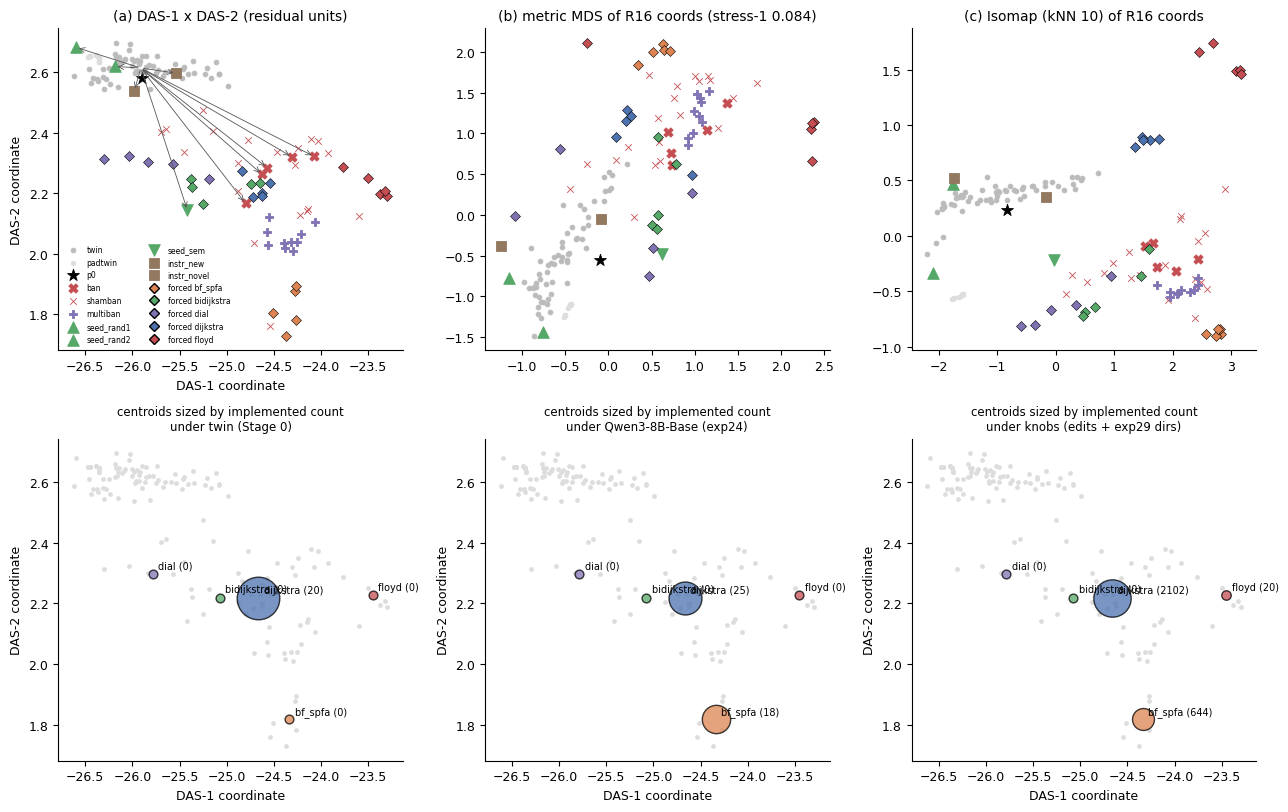

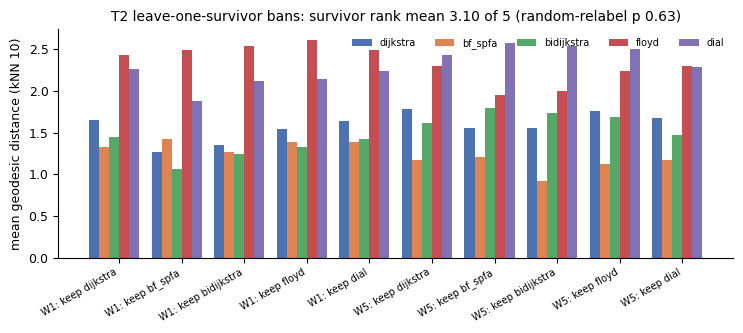

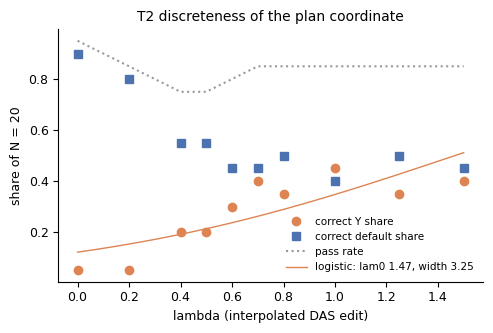

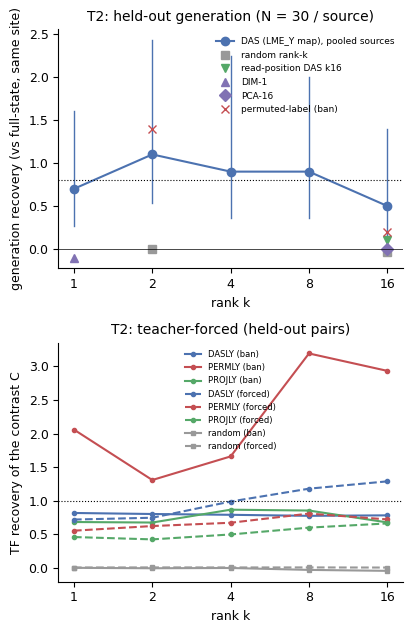

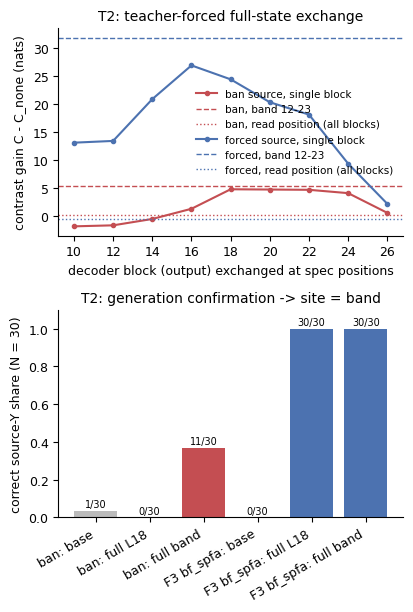

PDF + PNG copies written to figures/ (next to the notebook)


In [19]:
f4(m)           # F4 causal manifold: R16 activation coordinates, MDS, Isomap, centroids sized by implemented count
f5(m)           # F5 leave-one-survivor placement (kNN-10 geodesics)
f6(rr)          # F6 the lambda dial: graded, not a discrete switch
f2(p1, ["T2"])  # F2 top: generation recovery vs rank recomputed here; bottom: reported teacher-forced recoveries
f1(["T2"])      # F1 layer profile + generation confirmation (reported GPU-stage numbers)
print(f"PDF + PNG copies written to {FIG_DIR}/ (next to the notebook)")